# Etapa 3. Almacenamiento, lookup y caché

**Proyecto EDA 2026-2, Grupo 1, escenario B (comercio electrónico).**
Responsable de las etapas 3, 4 y 5: Carlos.

## Función de la etapa en el pipeline

La etapa 3 resuelve la **consulta puntual de productos** del escenario B. Dado un `parent_asin`, devuelve con baja latencia los datos del producto, su categoría, su precio y su disponibilidad. Además mantiene el estado del producto que cambia con el stream (vistas, compras, stock) y registra las interacciones de cada usuario con cada producto.

La etapa usa tres estructuras implementadas a mano. `dict`, `OrderedDict` y la búsqueda lineal se usan solo como líneas base. El código de la etapa está en `src/etapa_3/storage.py`; el notebook lo importa y muestra cada parte junto a su explicación.

| Estructura | Uso en la etapa | Costo por operación |
| --- | --- | --- |
| Tabla hash (direccionamiento abierto) | Índice `parent_asin` → posición del registro en disco, estado de cada producto | O(1) esperado |
| Caché LRU (tabla hash + lista doblemente enlazada) | Mantiene en memoria los productos consultados recientemente | O(1) |
| Matriz dispersa (DOK durante el stream, CSR al cerrar) | Interacciones usuario × producto | O(1) esperado por actualización |

## Proceso

```
eventos en orden de servicio (etapa 2)          catálogo (meta_office_products.parquet)
   │                                                │
   │                                                └─ archivo de registros en disco + índice hash
   ├─ 1. consultar el producto: caché LRU → si falla, índice hash + lectura en disco   O(1)
   ├─ 2. actualizar el estado del producto (contadores, stock, precio observado)      O(1)
   └─ 3. sumar el peso del evento en la matriz usuario × producto                     O(1)
   │
catálogo en disco, estado de productos y matriz CSR (etapas 4, 5, 7 y 9)
```

## Pasos del notebook

1. Configuración y lectura de la salida de la etapa 2.
2. Tabla hash propia.
3. Catálogo en disco con índice hash.
4. Caché LRU.
5. Matriz dispersa usuario × producto.
6. Ejecución de la etapa 3 sobre el stream.
7. Experimentos de complejidad.
8. Salida de la etapa 3.

## Paso 1. Configuración y entrada

La entrada es `data/interim/<CATEGORIA>/etapa2_eventos.jsonl`, generado por el notebook de la etapa 2. Cada línea es un ciclo de servicio con los eventos en el orden en que la etapa 2 los atiende. El catálogo se lee de `data/raw/meta_office_products.parquet`. La categoría y las rutas se toman de `src/config.py`. Las salidas de datos de la etapa se guardan en `data/interim/<CATEGORIA>/etapa_3/` y los resultados de los experimentos en `results/etapa_3/`. La celda muestra al final la plataforma y la semilla, que el enunciado pide reportar junto con los tiempos.

Los eventos **no se cargan completos en memoria**. La función `leer_eventos` lee el archivo línea por línea y entrega un evento a la vez. Esta primera pasada cuenta los eventos por tipo, suma los pesos que la matriz debe acumular y guarda la secuencia de productos consultados para el experimento B. Cada `parent_asin` de la secuencia se guarda una sola vez en memoria con `sys.intern`, porque un mismo producto aparece en muchos eventos.

Las mediciones de memoria del paso 6 y los experimentos del paso 7 guardan sus resultados en `results/etapa_3/` y se reutilizan si existen. Para medir de nuevo se cambia `REEJECUTAR_EXPERIMENTOS` a `True`. Cada archivo de resultados guarda el procesador y la versión de Python con que se midió, y las figuras muestran esa plataforma aunque el notebook se ejecute en otra máquina.

In [1]:
import gc
import inspect
import json
import platform
import random
import string
import sys
import time
import tracemalloc
from collections import Counter, OrderedDict
from itertools import islice
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import pyarrow as pa
import pyarrow.parquet as pq

# Raíz del proyecto: se sube de carpeta hasta encontrar la que contiene notebooks/ y data/
RAIZ = Path.cwd()
while not ((RAIZ / "notebooks").is_dir() and (RAIZ / "data").is_dir()) and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))       # para importar src/

from src import config
from src.etapa_3.storage import (CAPACIDAD_CACHE, CARPETA_ETAPA3, PESOS, RUTA_CATALOGO, RUTA_ESTADOS,
                                        RUTA_EVENTOS_ETAPA2, RUTA_MATRIZ, RUTA_METRICAS, AlmacenCatalogo,
                                        CacheLRU, EtapaAlmacenamiento, MatrizDispersa, TablaHash,
                                        cargar_matriz, construir_archivo_catalogo, guardar_matriz, leer_eventos)

SEED = config.SEED
CATEGORIA = config.CATEGORIA
CARPETA_RESULTADOS = config.CARPETA_RESULTADOS / "etapa_3"
CARPETA_RESULTADOS.mkdir(parents=True, exist_ok=True)
CARPETA_ETAPA3.mkdir(parents=True, exist_ok=True)
assert RUTA_EVENTOS_ETAPA2.exists(), "Falta la salida de la etapa 2. Ejecutar antes notebooks/etapa2_cola_prioridades.ipynb"

# Las mediciones guardadas en results/etapa_3/ se reutilizan. Con True se miden de nuevo.
REEJECUTAR_EXPERIMENTOS = False

# Plataforma (el enunciado pide reportarla junto con la semilla)
PLATAFORMA = {
    "sistema": platform.platform(),
    "procesador": platform.processor() or platform.machine(),
    "nucleos": psutil.cpu_count(logical=True),
    "ram_gb": round(psutil.virtual_memory().total / 1e9, 1),
    "python": platform.python_version(),
    "semilla": SEED,
}


def ruta_relativa(ruta):
    return ruta.relative_to(RAIZ).as_posix()


def resultados(ruta, medir_tabla):
    """Lee la tabla de resultados si existe. Si no, la mide con medir_tabla() y la guarda.

    Cada tabla guarda el procesador y la versión de Python con que se midió.
    """
    if ruta.exists() and not REEJECUTAR_EXPERIMENTOS:
        print(f"Resultados leídos de {ruta_relativa(ruta)}")
        return pd.read_csv(ruta, dtype={"procesador": str, "python": str})
    tabla = medir_tabla().assign(procesador=PLATAFORMA["procesador"], python=PLATAFORMA["python"])
    tabla.to_csv(ruta, index=False)
    print(f"Resultados guardados en {ruta_relativa(ruta)}")
    return tabla


def plataforma_de(tabla):
    """Procesador y versión de Python con que se midió una tabla de resultados."""
    return f"{tabla['procesador'].iloc[0]}, Python {tabla['python'].iloc[0]}"


# Primera pasada: conteo por tipo, suma de pesos y secuencia de productos consultados
tipos = Counter()
secuencia = []          # parent_asin de cada evento con producto, en orden de servicio
suma_pesos = 0.0
t0 = time.perf_counter()
for e in leer_eventos(RUTA_EVENTOS_ETAPA2):
    tipos[e.event_type] += 1
    if e.parent_asin is not None:
        secuencia.append(sys.intern(e.parent_asin))
        suma_pesos += PESOS.get(e.event_type, 0.0)
n_eventos = sum(tipos.values())

print(f"Categoría: {CATEGORIA}")
print(f"Entrada: {ruta_relativa(RUTA_EVENTOS_ETAPA2)}, {RUTA_EVENTOS_ETAPA2.stat().st_size / 1e9:.2f} GB, "
      f"{n_eventos:,} eventos en orden de servicio (lectura: {time.perf_counter() - t0:.0f} s)")
display(pd.Series(tipos).sort_values(ascending=False).to_frame("eventos"))
PLATAFORMA

Categoría: Office_Products
Entrada: data/interim/Office_Products/etapa2_eventos.jsonl, 3.58 GB, 9,940,617 eventos en orden de servicio (lectura: 71 s)


,eventos
view,2963552
purchase,1978936
cart,1942746
search,1487476
review,1467694
return,85195
payment_alert,15018


{'sistema': 'Windows-10-10.0.19045-SP0',
 'procesador': 'AMD64 Family 23 Model 24 Stepping 1, AuthenticAMD',
 'nucleos': 8,
 'ram_gb': 32.1,
 'python': '3.12.0',
 'semilla': 42}

## Paso 2. Tabla hash propia

La tabla hash es la base de las tres estructuras de la etapa. Se implementa con **direccionamiento abierto y sondeo lineal**.

- **Función hash.** CRC32 de la clave. El `hash()` de Python cambia en cada ejecución para los textos, y los resultados deben ser los mismos en cualquier ejecución y en cualquier máquina. Es el mismo criterio que usa la etapa 0.
- **Arreglos.** Dos listas paralelas guardan claves y valores. La capacidad es potencia de 2, así que la posición inicial es `hash & (capacidad − 1)`.
- **Colisiones.** Si la posición está ocupada por otra clave, se revisa la siguiente, y así hasta encontrar la clave o una posición vacía.
- **Eliminación.** Se deja una lápida en lugar de vaciar la posición, porque una posición vacía cortaría la secuencia de sondeo de las claves que están después.
- **Redimensionamiento.** Cuando las posiciones usadas (claves y lápidas) superan el 70 % de la capacidad, se reconstruye la tabla. La capacidad se duplica si las claves vivas superan el 35 % de la capacidad. Si no, solo se limpian las lápidas.

Con factor de carga α, el número esperado de posiciones revisadas es ½ (1 + 1 / (1 − α)) en una búsqueda exitosa y ½ (1 + 1 / (1 − α)²) en una búsqueda fallida, que es la que precede a la inserción de una clave nueva (Knuth, 1998). Con α ≤ 0.7 eso da como máximo 2.2 y 6.1 posiciones, por lo que cada operación cuesta O(1) esperado. Una reconstrucción cuesta O(n), pero solo ocurre después de un número de inserciones proporcional a la capacidad, así que el costo amortizado de la inserción también es O(1). El peor caso de una operación es O(n), si todas las claves caen en la misma secuencia de sondeo.

**Alternativa descartada.** El encadenamiento guarda en cada posición una lista con las claves que caen en ella. Tiene el mismo costo esperado, pero en Python cada lista es un objeto aparte, lo que suma memoria por posición y un acceso indirecto en cada consulta. El direccionamiento abierto guarda todo en dos arreglos planos, el mismo esquema que usa `dict`. Su punto débil es el agrupamiento primario del sondeo lineal, que se controla con el límite de 0.7 en el factor de carga.

In [2]:
print(inspect.getsource(TablaHash._buscar))
print(inspect.getsource(TablaHash.insertar))
print(inspect.getsource(TablaHash._reconstruir))

    def _buscar(self, clave):
        """Devuelve (posición, encontrada). Si no la encuentra, la posición es donde insertarla."""
        claves = self._claves
        mascara = len(claves) - 1
        i = hash_clave(clave) & mascara
        lapida = -1
        while True:
            k = claves[i]
            if k is None:
                return (lapida if lapida >= 0 else i), False
            if k is _BORRADO:
                if lapida < 0:
                    lapida = i
            elif k == clave:
                return i, True
            i = (i + 1) & mascara

    def insertar(self, clave, valor):
        """Inserta o actualiza la clave. Las claves no pueden ser None."""
        i, encontrada = self._buscar(clave)
        if encontrada:
            self._valores[i] = valor
            return
        if self._claves[i] is None:          # se reutiliza una lápida sin aumentar las usadas
            self._usadas += 1
        self._claves[i] = clave
        self._valores[i] = valor


In [3]:
# Ejemplo pequeño: se pide espacio para 8 claves. Con factor de carga máximo 0.7 hacen falta más de
# 8 / 0.7 ≈ 11.4 posiciones, así que la tabla empieza con 16, la potencia de 2 siguiente.
ejemplo = TablaHash(capacidad=8)
for asin in ["B001S28Q4Q", "B07XKRLQ2V", "B0BN9QX4XG", "B00006IFAV", "B08HMNKCCG", "B09W9M9Y4S"]:
    ejemplo.insertar(asin, len(asin))
ejemplo.eliminar("B0BN9QX4XG")
print(f"Capacidad: {ejemplo.capacidad} posiciones, {len(ejemplo)} claves vivas, "
      f"factor de carga {ejemplo.factor_carga():.3f}")
pd.DataFrame({"posición": range(ejemplo.capacidad),
              "clave": ["(lápida)" if k is not None and not isinstance(k, str) else k for k in ejemplo._claves]}
             ).set_index("posición").T

Capacidad: 16 posiciones, 5 claves vivas, factor de carga 0.312


posición,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
clave,NaN,B001S28Q4Q,NaN,NaN,NaN,B08HMNKCCG,B09W9M9Y4S,NaN,NaN,NaN,NaN,B07XKRLQ2V,NaN,(lápida),B00006IFAV,NaN


## Paso 3. Catálogo en disco con índice hash

Los registros completos del catálogo se escriben en un archivo en disco, un JSON por línea, y en memoria solo queda el índice `parent_asin` → `(offset, largo)`. Una consulta busca la posición en el índice y lee el registro con un `seek`. Así la memoria del índice depende solo del número de productos y no del tamaño de cada registro. El archivo y su índice sirven también como almacenamiento base para el B+Tree de la etapa 4.

Cada registro guarda el título, la categoría principal, la ruta de categorías y su último nivel, el precio, el rating promedio, el número de calificaciones y la tienda. El precio se convierte a número con `normalizar_precio` de la etapa 1, la misma función que limpia los precios del stream. Para los productos sin precio en el catálogo, la etapa usa el último precio observado en una compra.

La celda construye el índice, mide su memoria actual y pico con `tracemalloc` en una segunda construcción y compara el sondeo medio con la fórmula del paso 2.

**Alternativa descartada.** Cargar todos los registros en memoria evitaría las lecturas en disco, pero la memoria crecería con el tamaño de cada registro y no solo con el número de productos. La caché LRU del paso 4 conserva en memoria solo los registros consultados recientemente.

In [4]:
if not RUTA_CATALOGO.exists():
    t0 = time.perf_counter()
    n_registros = construir_archivo_catalogo()
    print(f"Archivo de registros escrito: {n_registros:,} productos en {time.perf_counter() - t0:.1f} s")

t0 = time.perf_counter()
almacen = AlmacenCatalogo()
t_indice = time.perf_counter() - t0
indice = almacen.indice
alfa = indice.factor_carga()

# Memoria del índice: se construye otra vez con tracemalloc, que hace más lenta la construcción
gc.collect()
tracemalloc.start()
almacen_medido = AlmacenCatalogo()
actual_indice, pico_indice = tracemalloc.get_traced_memory()
tracemalloc.stop()
almacen_medido.cerrar()
del almacen_medido

with open(RUTA_CATALOGO, "rb") as archivo:
    sin_precio = sum(1 for linea in archivo if b'"precio": null' in linea)

print(f"{ruta_relativa(RUTA_CATALOGO)}: {RUTA_CATALOGO.stat().st_size / 1e6:,.0f} MB, {len(almacen):,} registros")
print(f"Productos sin precio en el catálogo: {sin_precio:,} ({sin_precio / len(almacen):.1%})")
print(f"Índice construido en {t_indice:.1f} s. Capacidad {indice.capacidad:,}, factor de carga {alfa:.3f}")
print(f"Memoria del índice: actual {actual_indice / 1e6:.1f} MB, pico {pico_indice / 1e6:.1f} MB "
      f"({actual_indice / len(almacen):.0f} bytes por producto)")
print(f"Sondeo medio en búsqueda exitosa: {indice.sondeo_medio():.3f} posiciones "
      f"(teórico {0.5 * (1 + 1 / (1 - alfa)):.3f})")
almacen.leer("B001S28Q4Q")

Archivo de registros escrito: 710,503 productos en 9.5 s
data/interim/Office_Products/etapa_3/catalogo.jsonl: 303 MB, 710,503 registros
Productos sin precio en el catálogo: 427,969 (60.2%)
Índice construido en 3.6 s. Capacidad 1,048,576, factor de carga 0.678
Memoria del índice: actual 135.1 MB, pico 135.1 MB (190 bytes por producto)
Sondeo medio en búsqueda exitosa: 2.048 posiciones (teórico 2.051)


{'parent_asin': 'B001S28Q4Q',
 'title': 'Alliance Rubber 07706 Non-Latex Brites File Bands, Colored Elastic Bands, 1.5 oz Pic Pac Dispenser (Assorted Bright Colors and Sizes)',
 'main_category': 'Office Products',
 'categorias': ['Office Products',
  'Office & School Supplies',
  'Tape, Adhesives & Fasteners',
  'Rubber Bands'],
 'categoria_hoja': 'Rubber Bands',
 'precio': 2.68,
 'average_rating': 4.5,
 'rating_number': 665,
 'store': 'Alliance'}

## Paso 4. Caché LRU

La caché guarda en memoria los registros de los productos consultados recientemente y evita leerlos otra vez del disco. Cuando está llena, desaloja el producto usado hace más tiempo (*least recently used*).

- Una **tabla hash** propia da acceso O(1) al nodo de cada `parent_asin`.
- Una **lista doblemente enlazada** mantiene el orden de uso. El nodo más reciente queda junto a la cabeza y el menos reciente junto a la cola. Dos nodos centinela evitan los casos borde de lista vacía.
- Un acierto mueve el nodo a la cabeza. Un fallo inserta el nodo en la cabeza y, si se supera la capacidad, quita el nodo de la cola. Las tres operaciones cuestan O(1).

LRU es adecuada para este stream porque cada recorrido de compra consulta el mismo producto varias veces en pocos minutos (vista, carrito, compra y reseña). La capacidad por defecto es 50 000 productos. Se eligió con el experimento B1, que mide la tasa de aciertos según la capacidad sobre el stream real.

**Alternativas descartadas.** FIFO desaloja el producto que entró primero aunque se siga consultando, así que pierde los productos más demandados. LFU conserva los productos con más consultas acumuladas, pero necesita un contador por producto y una estructura ordenada por frecuencia, y retiene productos que fueron populares y dejaron de consultarse. LRU responde a la recencia, que es el patrón de un recorrido de compra, con O(1) por operación.

In [5]:
print(inspect.getsource(CacheLRU.obtener))
print(inspect.getsource(CacheLRU.poner))

    def obtener(self, clave, defecto=None):
        nodo = self._tabla.obtener(clave)
        if nodo is None:
            self.fallos += 1
            return defecto
        self.aciertos += 1
        self._quitar(nodo)
        self._al_frente(nodo)
        return nodo.valor

    def poner(self, clave, valor):
        nodo = self._tabla.obtener(clave)
        if nodo is not None:
            nodo.valor = valor
            self._quitar(nodo)
            self._al_frente(nodo)
            return
        nodo = _Nodo(clave, valor)
        self._tabla.insertar(clave, nodo)
        self._al_frente(nodo)
        if len(self._tabla) > self.capacidad:
            ultimo = self._cola.ant
            self._quitar(ultimo)
            self._tabla.eliminar(ultimo.clave)
            self.desalojos += 1



## Paso 5. Matriz dispersa usuario × producto

La matriz registra la intensidad de la interacción de cada usuario con cada producto. Cada evento suma un peso en la celda (usuario, producto).

| Evento | Peso | Justificación |
| --- | --- | --- |
| `view` | 1 | Interés débil |
| `cart` | 2 | Intención de compra |
| `purchase` | 4 | Interacción más fuerte |
| `review` | 1 | Confirma la relación con el producto |
| `return` | −4 | Anula la compra devuelta |

Las búsquedas no tienen producto y las alertas de pago no son interacciones con el producto, así que no se registran.

Una matriz densa necesitaría una celda de 8 bytes por cada par usuario × producto, aunque casi todas serían cero. El paso 6 calcula su tamaño con las dimensiones de la matriz real. Por eso se usan dos representaciones dispersas.

- **Durante el stream, DOK** (*dictionary of keys*). Las celdas no nulas se guardan en una tabla hash propia con clave entera `fila << 32 | columna`. Sumar un peso cuesta O(1) esperado y la matriz crece sin conocer de antemano el número de usuarios ni de productos.
- **Al cerrar, CSR** (*compressed sparse row*). Tres arreglos compactos `indptr`, `indices` y `datos`. Ocupa O(filas + nnz) y da acceso a la fila de un usuario en O(1) más su número de elementos. La conversión ordena las celdas en O(nnz log nnz). La transpuesta (producto × usuario) se obtiene con un conteo por columnas en O(filas + columnas + nnz).

Las celdas con peso ≤ 0 (compra devuelta) se omiten en la CSR.

**Alternativas descartadas.** COO guarda tres listas de fila, columna y valor. Agrega una interacción en O(1), pero repite la celda cada vez que el usuario vuelve al producto y no permite consultar el valor de una celda sin agregar antes las repeticiones. LIL guarda una lista por fila y obliga a recorrer la fila para encontrar la columna. CSC es CSR por columnas. Aquí se obtiene como la transpuesta de la CSR, que da la vista producto × usuario que usa la etapa 7.

In [6]:
print(inspect.getsource(MatrizDispersa.sumar))
print(inspect.getsource(MatrizDispersa.a_csr))

    def sumar(self, usuario, asin, peso):
        fila = self._indice(self.fila_de, self.usuarios, usuario)
        columna = self._indice(self.columna_de, self.productos, asin)
        clave = fila << 32 | columna
        self.celdas.insertar(clave, self.celdas.obtener(clave, 0.0) + peso)

    def a_csr(self):
        """Convierte a CSR. Las celdas con peso <= 0 (por ejemplo, compra devuelta) se omiten.

        El ordenamiento por clave entera ordena por (fila, columna). O(nnz log nnz).
        """
        n_filas, n_columnas = self.forma
        celdas = sorted((k, v) for k, v in self.celdas.items() if v > 0)
        indptr = array("q", [0]) * (n_filas + 1)
        indices = array("i")
        datos = array("d")
        for clave, v in celdas:
            indptr[(clave >> 32) + 1] += 1
            indices.append(clave & 0xFFFFFFFF)
            datos.append(v)
        for i in range(n_filas):
            indptr[i + 1] += indptr[i]
        return MatrizCSR(indptr, indices, datos, n_co

## Paso 6. Ejecución de la etapa 3

Cada evento de la etapa 2 pasa por `EtapaAlmacenamiento.procesar`, en el orden de servicio.

1. Si el evento tiene producto, se consulta el registro a través de la caché.
2. Se actualiza el estado dinámico del producto. El estado se crea solo para productos con actividad. El stock inicial es sintético y estable por producto, entre 5 y 50 unidades, porque el dataset no trae inventario. Una compra descuenta una unidad y una devolución la repone. Un producto agotado se repone 48 horas después de agotarse.
3. Se suma el peso del evento en la matriz.

Se hacen dos pasadas con los mismos eventos, leídos otra vez del archivo en cada una. La primera mide el tiempo sin `tracemalloc` y es la que produce la salida. Su tiempo incluye la lectura y decodificación del archivo. La segunda mide la memoria actual y pico con `tracemalloc`, que hace más lenta la ejecución, y su resultado se guarda en `results/etapa_3/etapa_memoria.csv`. El índice del catálogo ya existe y queda fuera de la medición.

Las métricas de la ejecución se guardan al terminar la primera pasada, porque las consultas de ejemplo de este paso también pasan por la caché y cambiarían sus contadores.

In [7]:
print(inspect.getsource(EtapaAlmacenamiento.procesar))

    def procesar(self, evento):
        """Actualiza la etapa con un evento limpio que sale de la etapa 2."""
        m = self.metricas
        m["eventos"] += 1
        asin = evento.parent_asin
        if asin is None:                              # búsquedas
            m["sin_producto"] += 1
            return
        if self.consultar_producto(asin) is None:
            m["fuera_de_catalogo"] += 1

        e = self.estados.obtener(asin)
        if e is None:
            e = EstadoProducto(stock_inicial(asin))
            self.estados.insertar(asin, e)
        tipo = evento.event_type
        ts = evento.ts
        if e.agotado_desde is not None and ts - e.agotado_desde >= REPOSICION_S:
            e.stock = stock_inicial(asin)              # reposición
            e.agotado_desde = None
            m["reposiciones"] += 1

        if tipo == "view":
            e.vistas += 1
        elif tipo == "cart":
            e.carritos += 1
        elif tipo == "purchase":
            e.comp

In [8]:
etapa = EtapaAlmacenamiento(almacen, capacidad_cache=CAPACIDAD_CACHE)
lecturas_antes = almacen.lecturas
t0 = time.perf_counter()
for evento in leer_eventos(RUTA_EVENTOS_ETAPA2):
    etapa.procesar(evento)
t_etapa = time.perf_counter() - t0
lecturas_etapa = almacen.lecturas - lecturas_antes

# Métricas al terminar la pasada, antes de cualquier otra consulta a la caché
m = Counter(etapa.metricas)
cache = etapa.cache
estados = pd.DataFrame(etapa.tabla_estados())
csr = etapa.matriz.a_csr()
filas_matriz, columnas_matriz = etapa.matriz.forma
METRICAS = {
    "eventos": m["eventos"], "sin_producto": m["sin_producto"], "fuera_de_catalogo": m["fuera_de_catalogo"],
    "segundos": round(t_etapa, 3), "us_por_evento": round(t_etapa / m["eventos"] * 1e6, 2),
    "cache": {"capacidad": cache.capacidad, "aciertos": cache.aciertos, "fallos": cache.fallos,
              "desalojos": cache.desalojos, "tasa_aciertos": round(cache.tasa_aciertos(), 4)},
    "lecturas_disco": lecturas_etapa,
    "productos_con_estado": len(etapa.estados), "reposiciones": m["reposiciones"],
    "compras_sin_stock": int(estados["ventas_sin_stock"].sum()),
    "productos_con_compras_sin_stock": int((estados["ventas_sin_stock"] > 0).sum()),
    "matriz": {"usuarios": filas_matriz, "productos": columnas_matriz, "celdas_dok": len(etapa.matriz.celdas),
               "nnz_csr": csr.nnz, "bytes_csr": csr.bytes(), "bytes_densa": filas_matriz * columnas_matriz * 8},
}


def medir_memoria_etapa():
    """Memoria actual y pico de una segunda pasada completa de la etapa."""
    etapa_memoria = EtapaAlmacenamiento(almacen, capacidad_cache=CAPACIDAD_CACHE)
    gc.collect()
    tracemalloc.start()
    for evento in leer_eventos(RUTA_EVENTOS_ETAPA2):
        etapa_memoria.procesar(evento)
    actual, pico = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return pd.DataFrame([{"actual_mb": actual / 1e6, "pico_mb": pico / 1e6}])


memoria_etapa = resultados(CARPETA_RESULTADOS / "etapa_memoria.csv", medir_memoria_etapa)
gc.collect()
METRICAS["memoria_actual_mb"] = round(float(memoria_etapa["actual_mb"].iloc[0]), 1)
METRICAS["memoria_pico_mb"] = round(float(memoria_etapa["pico_mb"].iloc[0]), 1)

compras = tipos["purchase"]
print(f"Eventos procesados: {m['eventos']:,} en {t_etapa:.1f} s ({METRICAS['us_por_evento']:.1f} µs por evento)")
print(f"Memoria de la etapa sin el índice del catálogo: actual {METRICAS['memoria_actual_mb']:,.0f} MB, "
      f"pico {METRICAS['memoria_pico_mb']:,.0f} MB")
print(f"Búsquedas sin producto: {m['sin_producto']:,}   productos fuera del catálogo: {m['fuera_de_catalogo']:,}")
print(f"Caché LRU: {cache.aciertos:,} aciertos, {cache.fallos:,} fallos, tasa de aciertos {cache.tasa_aciertos():.1%}, "
      f"{cache.desalojos:,} desalojos")
print(f"Lecturas en disco: {lecturas_etapa:,}")
print(f"Productos con estado: {len(etapa.estados):,}   reposiciones: {m['reposiciones']:,}")
print(f"Compras sin stock: {METRICAS['compras_sin_stock']:,} de {compras:,} "
      f"({METRICAS['compras_sin_stock'] / compras:.1%}), en {METRICAS['productos_con_compras_sin_stock']:,} productos")
print(f"Matriz: {filas_matriz:,} usuarios × {columnas_matriz:,} productos, "
      f"{len(etapa.matriz.celdas):,} celdas no nulas en la DOK, {csr.nnz:,} con peso positivo en la CSR")
print(f"Memoria de la CSR: {csr.bytes() / 1e6:.1f} MB. Una matriz densa de las mismas dimensiones ocuparía "
      f"{filas_matriz * columnas_matriz * 8 / 1e12:.2f} TB")

Resultados guardados en results/etapa_3/etapa_memoria.csv
Eventos procesados: 9,940,617 en 202.0 s (20.3 µs por evento)
Memoria de la etapa sin el índice del catálogo: actual 500 MB, pico 516 MB
Búsquedas sin producto: 1,487,476   productos fuera del catálogo: 0
Caché LRU: 8,080,834 aciertos, 372,307 fallos, tasa de aciertos 95.6%, 322,307 desalojos
Lecturas en disco: 372,307
Productos con estado: 195,019   reposiciones: 50,906
Compras sin stock: 73,678 de 1,978,936 (3.7%), en 11,785 productos
Matriz: 1,096,990 usuarios × 195,019 productos, 2,169,391 celdas no nulas en la DOK, 2,169,111 con peso positivo en la CSR
Memoria de la CSR: 34.8 MB. Una matriz densa de las mismas dimensiones ocuparía 1.71 TB


### Verificación

- Cada evento con producto hace una consulta a la caché, así que aciertos + fallos debe ser igual al número de eventos con producto de la primera pasada.
- Cada fallo lee una vez el disco, así que las lecturas deben ser iguales a los fallos.
- La suma de la matriz debe coincidir con la suma de los pesos de los eventos.
- La CSR debe tener exactamente las celdas de la DOK con peso positivo.

In [9]:
con_producto = m["eventos"] - m["sin_producto"]
assert cache.aciertos + cache.fallos == con_producto == len(secuencia)
assert lecturas_etapa == cache.fallos
suma_matriz = sum(v for _, v in etapa.matriz.celdas.items())
assert abs(suma_pesos - suma_matriz) < 1e-6
assert csr.nnz == sum(1 for _, v in etapa.matriz.celdas.items() if v > 0)
print(f"Consultas = eventos con producto = {con_producto:,}")
print(f"Lecturas en disco = fallos de la caché = {cache.fallos:,}")
print(f"Suma de pesos = suma de la matriz = {suma_matriz:,.0f}")
print(f"Celdas de la CSR = celdas de la DOK con peso positivo = {csr.nnz:,}")

Consultas = eventos con producto = 8,453,141
Lecturas en disco = fallos de la caché = 372,307
Suma de pesos = suma de la matriz = 15,891,702
Celdas de la CSR = celdas de la DOK con peso positivo = 2,169,111


### Consulta de productos

La consulta del escenario B devuelve los datos del catálogo junto con la disponibilidad y el stock actuales. Se muestran los cinco productos más comprados en el stream.

In [10]:
mas_comprados = estados.nlargest(5, "compras")["parent_asin"]
pd.DataFrame([{k: v for k, v in etapa.ficha(a).items() if k not in ("categorias", "main_category")}
              for a in mas_comprados])

,parent_asin,title,categoria_hoja,precio,average_rating,rating_number,store,disponible,stock
0,B0BN478RWJ,HP DeskJet 2755e Wireless Color All-in-One Pri...,Inkjet Printers,59.99,4.1,31419,HP,True,15
1,B087S2JRXY,"Amazon Basics 15-Sheet Cross-Cut Paper, CD Cre...",Shredders,131.99,4.6,201726,Amazon Basics,True,5
2,B0B3MX7LVG,"EZlifego Double Sided Tape Heavy Duty, Extra L...",Mounting Tape,10.99,4.3,90934,EZlifego,True,15
3,B0BF98LWMZ,TN436 ColorKing Compatible Toner Cartridge Rep...,Toner Cartridges,62.99,5.0,8,Colorking,True,31
4,B0BZ67T58M,Office Chair Wheels Replacement Rubber Chair c...,Casters,39.99,4.8,44539,LIFELONG,True,2


In [11]:
estados[["vistas", "carritos", "compras", "devoluciones", "resenas", "agotamientos", "ventas_sin_stock"]].describe().round(2)

,vistas,carritos,compras,devoluciones,resenas,agotamientos,ventas_sin_stock
count,195019.00,195019.00,195019.00,195019.00,195019.00,195019.00,195019.00
mean,15.20,9.96,10.15,0.44,7.53,0.31,0.38
std,55.34,31.92,32.49,2.53,27.35,2.17,8.77
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,2.00,1.00,1.00,0.00,1.00,0.00,0.00
50%,4.00,3.00,3.00,0.00,2.00,0.00,0.00
75%,11.00,8.00,8.00,0.00,5.00,0.00,0.00
max,5604.00,2715.00,2765.00,459.00,2776.00,338.00,1673.00


## Paso 7. Experimentos de complejidad

### Diseño del experimento

Se hacen tres experimentos con las estructuras de `src/etapa_3/storage.py`, el mismo código que usa la etapa en el paso 6.

| Experimento | Métodos | Complejidad esperada |
| --- | --- | --- |
| A. Tabla hash | `TablaHash` (propia), `dict` (en C) y búsqueda lineal en una lista | Construcción O(n); consulta O(1) en las tablas hash y O(n) en la lista; memoria O(n) |
| B. Caché LRU | `CacheLRU` (propia), LRU con `OrderedDict` (en C) y lectura del archivo sin caché | O(1) por acceso; tasa de aciertos creciente con la capacidad; memoria O(capacidad) |
| C. Matriz dispersa | DOK propia, DOK con `dict` (en C), conversión a CSR y matriz densa | Construcción O(n); conversión O(nnz log nnz); memoria O(nnz) frente a O(filas × columnas) |

**Tipos de medición.**

- **Construcción.** Cada repetición construye la estructura con n elementos, así que cuesta O(n). Se mide en la tabla hash con n claves (A) y en la matriz con n interacciones, junto con su conversión a CSR (C).
- **Costo por operación.** La estructura se construye una vez por tamaño, fuera de la medición, y cada repetición mide un bloque fijo de 10 000 operaciones. El costo de una repetición no depende de n. Se mide en la consulta de la tabla hash (A) y en el acceso a la caché (B).
- **Memoria.** Actual y pico con `tracemalloc`, en una pasada aparte, porque el rastreo hace más lento el código. Solo se rastrea la estructura, no la generación de los datos. La memoria actual es la que ocupa la estructura terminada y la pico, el máximo durante su construcción. Se hace una medición por tamaño y método, porque las asignaciones no varían entre repeticiones.
- **Valores deterministas.** La tasa de aciertos sobre el stream real depende solo de la secuencia de consultas y de la capacidad. Se calcula una vez.

**Tamaños y repeticiones.**

- **De 1K a 1M.** 100 repeticiones por tamaño y por método.
- **10M.** Las mediciones por bloque tienen 100 repeticiones también en 10M. Las construcciones se hacen una vez, y la celda de cada experimento reporta cuánto tardarían 100 repeticiones, que es la justificación de no repetirlas.
- **Búsqueda lineal.** Hasta 1M, con menos consultas por repetición, porque cada consulta recorre O(n) elementos. No se mide en 10M porque es la línea base O(n) y no una estructura de la etapa.

**Condiciones de medición.**

- **Reloj.** `time.perf_counter`, con el recolector de basura desactivado durante cada medición. La estructura medida se libera fuera del intervalo medido.
- **Datos.** Se generan con la semilla 42 antes de medir. En cada tamaño, todos los métodos reciben los mismos datos. Los objetos que ya existen al empezar el paso (eventos, catálogo y claves) se excluyen de las colecciones del recolector con `gc.freeze`, para que la limpieza previa a cada medición no los recorra.
- **Plataforma y semilla.** Las del paso 1. Cada archivo de resultados guarda el procesador y la versión de Python con que se midió.
- **Resultados.** Se guardan en `results/etapa_3/` y se reutilizan si existen. Para medir de nuevo se cambia `REEJECUTAR_EXPERIMENTOS` a `True` en el paso 1.

In [12]:
TAMANOS = [1_000, 10_000, 100_000, 1_000_000]   # 100 repeticiones
N_UNICO = 10_000_000                              # construcción: una corrida; bloques: 100 repeticiones
TAMANOS_TODOS = TAMANOS + [N_UNICO]
REPETICIONES = 100
BLOQUE = 10_000                                   # operaciones por repetición en las mediciones por bloque
ALFABETO = string.ascii_uppercase + string.digits


def generar_asins(n, semilla=SEED):
    """n textos distintos con formato de ASIN. Las claves de un tamaño menor son un prefijo de las de uno mayor."""
    rng = random.Random(semilla)
    vistos = set()                     # set solo para garantizar claves distintas al generar
    claves = []
    while len(claves) < n:
        k = "B" + "".join(rng.choices(ALFABETO, k=9))
        if k not in vistos:
            vistos.add(k)
            claves.append(k)
    return claves


def medir(funcion, *args, recolectar=True):
    """(segundos, resultado) de funcion(*args), con el recolector de basura desactivado.

    El resultado se devuelve para que la estructura se libere fuera del intervalo medido.
    """
    if recolectar:
        gc.collect()
    gc.disable()
    try:
        t0 = time.perf_counter()
        resultado = funcion(*args)
        segundos = time.perf_counter() - t0
    finally:
        gc.enable()
    return segundos, resultado


def medir_memoria(funcion, *args):
    """(resultado, memoria actual, memoria pico) en bytes. Solo se rastrea lo que asigna funcion."""
    gc.collect()
    tracemalloc.start()
    resultado = funcion(*args)
    actual, pico = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return resultado, actual, pico


def resumir(tabla, columnas=("metodo", "n")):
    """Promedio y desviación estándar del tiempo total y del tiempo por operación."""
    tabla = tabla.assign(ns_por_operacion=tabla["segundos"] / tabla["operaciones"] * 1e9)
    return (tabla.groupby(list(columnas), sort=False)
            .agg(promedio_s=("segundos", "mean"), desv_est_s=("segundos", "std"),
                 ns_por_operacion=("ns_por_operacion", "mean"), desv_ns=("ns_por_operacion", "std"),
                 repeticiones=("segundos", "count"))
            .reset_index())


def pendientes(resumen, valor, esperado, hasta=None):
    """Pendiente log-log de valor frente a n, ajustada por mínimos cuadrados para cada método."""
    filas = []
    for metodo, datos in resumen.groupby("metodo", sort=False):
        if hasta is not None:
            datos = datos[datos["n"] <= hasta]
        k, _ = np.polyfit(np.log10(datos["n"]), np.log10(datos[valor]), 1)
        filas.append({"metodo": metodo, "pendiente_empirica": round(k, 2), "esperado": esperado[metodo],
                      "rango_n": f"{datos['n'].min():,} a {datos['n'].max():,}"})
    return pd.DataFrame(filas)


def corrida_unica(resumen):
    """Tiempo de las construcciones medidas una vez con 10M y lo que tardarían 100 repeticiones."""
    unicas = resumen[(resumen["n"] == N_UNICO) & (resumen["repeticiones"] == 1)]
    segundos = unicas["promedio_s"].sum()
    print(f"Construcciones con 10M, una corrida: {segundos / 60:.1f} min de medición. 100 repeticiones tomarían "
          f"unas {100 * segundos / 3600:.1f} h solo en tiempo, sin contar la pasada de memoria.")


def referencia(ax, n, base_n, base_y, forma, estilo, etiqueta):
    """Curva teórica anclada en el punto (base_n, base_y)."""
    n = np.array(n, dtype=float)
    ax.plot(n, base_y * forma(n) / forma(float(base_n)), estilo, lw=1, label=f"referencia {etiqueta}")


def ejes_loglog(ax, titulo, xlabel, ylabel):
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=8)


# Claves de los experimentos A y B3: ASIN distintos generados una vez. Cada tamaño usa un prefijo.
# B3 necesita n + n/10 claves distintas, así que se generan 11 millones.
t0 = time.perf_counter()
CLAVES = generar_asins(N_UNICO + N_UNICO // 10)
print(f"{len(CLAVES):,} claves generadas en {time.perf_counter() - t0:.0f} s")

# Los objetos que ya existen quedan fuera de las colecciones del recolector
gc.collect()
gc.freeze()

11,000,000 claves generadas en 21 s


### Experimento A. Tabla hash

Para cada n se construye la tabla con las n primeras claves y se consultan claves existentes elegidas al azar.

- **Construcción.** n inserciones. Debe ser O(n), con pendiente log-log cercana a 1 y tiempo por inserción casi constante.
- **Consulta.** Bloques de 10 000 consultas sobre la tabla ya construida. En las tablas hash debe ser O(1), con pendiente cercana a 0 en el tiempo por consulta. La búsqueda lineal en una lista debe tener pendiente cercana a 1. Se hacen 200, 50, 10 y 3 búsquedas lineales por repetición en 1K, 10K, 100K y 1M.
- **Memoria.** Actual y pico al construir la tabla. Las claves ya existen antes de la medición y no se cuentan. El pico incluye las reconstrucciones, durante las cuales conviven los arreglos viejos y los nuevos.

In [13]:
def construir_tabla(claves):
    t = TablaHash()
    for i, k in enumerate(claves):
        t.insertar(k, i)
    return t


def construir_dict(claves):
    d = {}
    for i, k in enumerate(claves):
        d[k] = i
    return d


def consultar_tabla(tabla, consultas):
    for k in consultas:
        tabla.obtener(k)


def consultar_dict(d, consultas):
    for k in consultas:
        d.get(k)


def buscar_lineal(lista, clave):
    for i, k in enumerate(lista):
        if k == clave:
            return i
    return -1


def consultar_lineal(lista, consultas):
    for k in consultas:
        buscar_lineal(lista, k)


TABLA = "TablaHash (propia)"
LINEAL = "búsqueda lineal (lista)"
METODOS_A = {TABLA: (construir_tabla, consultar_tabla), "dict (C)": (construir_dict, consultar_dict)}
CONSULTAS_LINEAL = {1_000: 200, 10_000: 50, 100_000: 10, 1_000_000: 3}

# Las dos tablas tienen el mismo contenido y responden igual que la búsqueda lineal
muestra = CLAVES[:10_000]
tabla_prueba, dict_prueba = construir_tabla(muestra), construir_dict(muestra)
assert dict(tabla_prueba.items()) == dict_prueba
assert all(tabla_prueba.obtener(k) == dict_prueba[k] == buscar_lineal(muestra, k) for k in muestra[::97])
assert tabla_prueba.obtener(CLAVES[10_000]) is None
del muestra, tabla_prueba, dict_prueba
print("Las tres implementaciones dan el resultado esperado.")


def medir_a():
    filas = []
    for n in TAMANOS_TODOS:
        claves = CLAVES[:n]
        estructuras = {}                       # la última construcción de cada método se usa en las consultas
        for rep in range(REPETICIONES if n <= TAMANOS[-1] else 1):
            for metodo, (construir, _) in METODOS_A.items():
                segundos, estructuras[metodo] = medir(construir, claves)
                filas.append({"operacion": "construccion", "metodo": metodo, "n": n, "repeticion": rep,
                              "operaciones": n, "segundos": segundos})
        rng = random.Random(SEED + n)
        gc.collect()
        for rep in range(REPETICIONES):
            consultas = [claves[rng.randrange(n)] for _ in range(BLOQUE)]
            for metodo, (_, consultar) in METODOS_A.items():
                segundos, _ = medir(consultar, estructuras[metodo], consultas, recolectar=False)
                filas.append({"operacion": "consulta", "metodo": metodo, "n": n, "repeticion": rep,
                              "operaciones": BLOQUE, "segundos": segundos})
            if n in CONSULTAS_LINEAL:
                consultas_l = consultas[:CONSULTAS_LINEAL[n]]
                segundos, _ = medir(consultar_lineal, claves, consultas_l, recolectar=False)
                filas.append({"operacion": "consulta", "metodo": LINEAL, "n": n, "repeticion": rep,
                              "operaciones": len(consultas_l), "segundos": segundos})
        del claves, estructuras
        print(f"n = {n:>10,} medido")
    return pd.DataFrame(filas)


tiempos_a = resultados(CARPETA_RESULTADOS / "hash_tiempos.csv", medir_a)
resumen_a = resumir(tiempos_a, ("operacion", "metodo", "n"))
corrida_unica(resumen_a[resumen_a["operacion"] == "construccion"])
resumen_a.round({"promedio_s": 6, "desv_est_s": 6, "ns_por_operacion": 1, "desv_ns": 1})

Las tres implementaciones dan el resultado esperado.
n =      1,000 medido
n =     10,000 medido
n =    100,000 medido
n =  1,000,000 medido
n = 10,000,000 medido
Resultados guardados en results/etapa_3/hash_tiempos.csv
Construcciones con 10M, una corrida: 0.7 min de medición. 100 repeticiones tomarían unas 1.1 h solo en tiempo, sin contar la pasada de memoria.


,operacion,metodo,n,promedio_s,desv_est_s,ns_por_operacion,desv_ns,repeticiones
0,construccion,TablaHash (propia),1000,0.002970,0.000259,2970.1,258.7,100
1,construccion,dict (C),1000,0.000087,0.000011,86.9,11.2,100
2,consulta,TablaHash (propia),1000,0.006599,0.000489,659.9,48.9,100
3,consulta,dict (C),1000,0.000490,0.000032,49.0,3.2,100
4,consulta,búsqueda lineal (lista),1000,0.005268,0.000393,26341.8,1965.7,100
5,construccion,TablaHash (propia),10000,0.026913,0.001212,2691.3,121.2,100
6,construccion,dict (C),10000,0.000959,0.000158,95.9,15.8,100
7,consulta,TablaHash (propia),10000,0.007611,0.000920,761.1,92.0,100
8,consulta,dict (C),10000,0.000998,0.000238,99.8,23.8,100
9,consulta,búsqueda lineal (lista),10000,0.015711,0.001449,314230.0,28973.6,100


#### Memoria actual y pico de la tabla hash

In [14]:
def medir_memoria_a():
    filas = []
    for n in TAMANOS_TODOS:
        claves = CLAVES[:n]
        for metodo, (construir, _) in METODOS_A.items():
            estructura, actual, pico = medir_memoria(construir, claves)
            del estructura
            filas.append({"metodo": metodo, "n": n, "actual_mb": actual / 1e6, "pico_mb": pico / 1e6})
        del claves
        print(f"n = {n:>10,} medido")
    return pd.DataFrame(filas)


memoria_a = resultados(CARPETA_RESULTADOS / "hash_memoria.csv", medir_memoria_a)
memoria_a["bytes_por_clave_actual"] = memoria_a["actual_mb"] * 1e6 / memoria_a["n"]
memoria_a["bytes_por_clave_pico"] = memoria_a["pico_mb"] * 1e6 / memoria_a["n"]
memoria_a.pivot(index="n", columns="metodo",
                values=["actual_mb", "pico_mb", "bytes_por_clave_actual", "bytes_por_clave_pico"]).round(1)

n =      1,000 medido
n =     10,000 medido
n =    100,000 medido
n =  1,000,000 medido
n = 10,000,000 medido
Resultados guardados en results/etapa_3/hash_memoria.csv


actual_mb                     pico_mb           \
metodo   TablaHash (propia) dict (C) TablaHash (propia) dict (C)   
n                                                                  
1000                    0.1      0.0                0.1      0.1   
10000                   0.7      0.5                0.9      0.5   
100000                  7.1      6.6               13.7      8.2   
1000000                61.7     58.8              109.5     65.7   
10000000              548.5    526.1              878.2    526.1   

         bytes_por_clave_actual          bytes_por_clave_pico           
metodo       TablaHash (propia) dict (C)   TablaHash (propia) dict (C)  
n                                                                       
1000                       95.5     47.0                101.3     51.2  
10000                      65.1     48.1                 85.1     48.1  
100000                     71.0     66.4                137.5     82.1  
1000000                    61.7     58.8                109.5     65.7  
10000000                   54.9     52.6                 87.8     52.6

#### Escalabilidad en escala log-log

En una gráfica log-log, un costo de la forma T(n) = c·nᵏ aparece como una recta de pendiente k. Un costo O(n) da una pendiente cercana a 1 y un costo O(1) por operación, una pendiente cercana a 0 en el tiempo por operación. Las líneas punteadas son las referencias teóricas, ancladas en el primer punto del método indicado. Los puntos huecos son las construcciones con 10M, medidas una vez. La pendiente de las construcciones se ajusta con mínimos cuadrados sobre los promedios de 1K a 1M. La de las mediciones por bloque y la de la memoria se ajustan de 1K a 10M. Este criterio se usa también en los experimentos B y C.

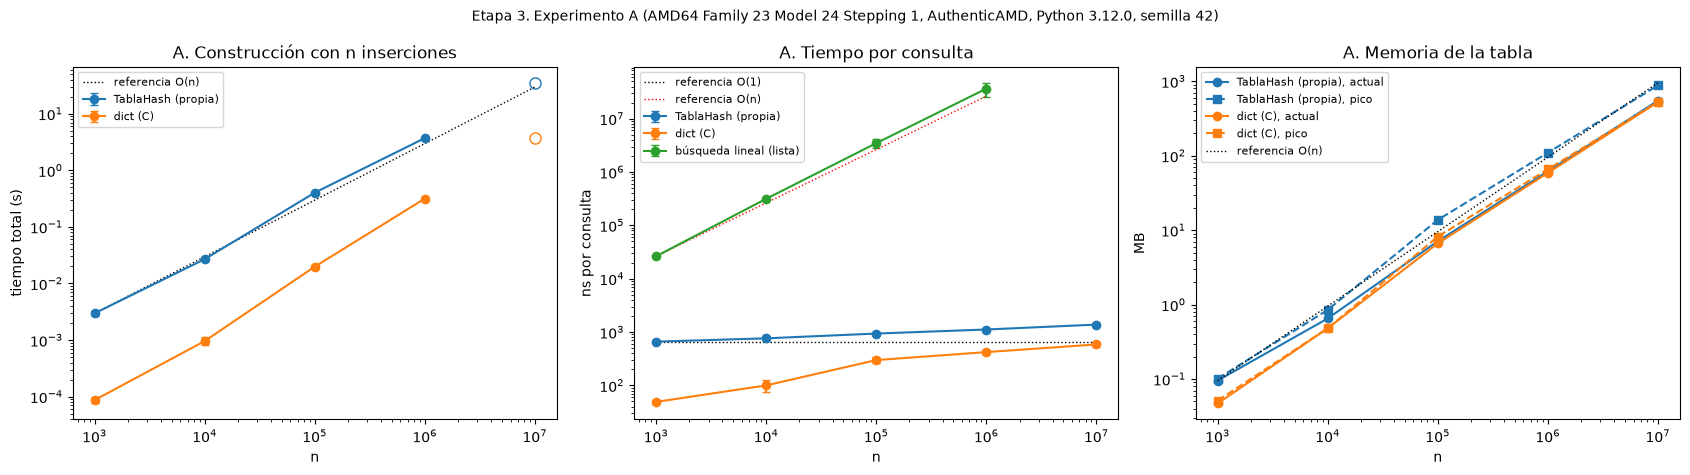

,metodo,pendiente_empirica,esperado,rango_n
0,TablaHash (propia),1.05,≈1 (n),"1,000 a 1,000,000"
1,dict (C),1.20,≈1 (n),"1,000 a 1,000,000"


,metodo,pendiente_empirica,esperado,rango_n
0,TablaHash (propia),0.08,≈0 (1),"1,000 a 10,000,000"
1,dict (C),0.28,≈0 (1),"1,000 a 10,000,000"
2,búsqueda lineal (lista),1.05,≈1 (n),"1,000 a 1,000,000"


,metodo,pendiente_empirica,esperado,rango_n
0,TablaHash (propia),0.95,≈1 (n),"1,000 a 10,000,000"
1,dict (C),1.02,≈1 (n),"1,000 a 10,000,000"


In [15]:
construccion = resumen_a[resumen_a["operacion"] == "construccion"]
consulta = resumen_a[resumen_a["operacion"] == "consulta"]

fig, ejes = plt.subplots(1, 3, figsize=(17, 4.8))
for metodo, datos in construccion.groupby("metodo", sort=False):
    repetidas = datos[datos["n"] <= TAMANOS[-1]]
    barras = ejes[0].errorbar(repetidas["n"], repetidas["promedio_s"], yerr=repetidas["desv_est_s"], marker="o",
                              capsize=3, label=metodo)
    unica = datos[datos["n"] == N_UNICO]
    ejes[0].plot(unica["n"], unica["promedio_s"], marker="o", markerfacecolor="none", markersize=8,
                 linestyle="none", color=barras[0].get_color())
base = construccion[construccion["metodo"] == TABLA].iloc[0]
referencia(ejes[0], TAMANOS_TODOS, base["n"], base["promedio_s"], lambda n: n, "k:", "O(n)")

for metodo, datos in consulta.groupby("metodo", sort=False):
    ejes[1].errorbar(datos["n"], datos["ns_por_operacion"], yerr=datos["desv_ns"], marker="o", capsize=3,
                     label=metodo)
base = consulta[consulta["metodo"] == TABLA].iloc[0]
referencia(ejes[1], TAMANOS_TODOS, base["n"], base["ns_por_operacion"], lambda n: n ** 0, "k:", "O(1)")
base = consulta[consulta["metodo"] == LINEAL].iloc[0]
referencia(ejes[1], TAMANOS, base["n"], base["ns_por_operacion"], lambda n: n, "r:", "O(n)")

for metodo, datos in memoria_a.groupby("metodo", sort=False):
    linea = ejes[2].plot(datos["n"], datos["actual_mb"], marker="o", label=f"{metodo}, actual")
    ejes[2].plot(datos["n"], datos["pico_mb"], marker="s", linestyle="--", color=linea[0].get_color(),
                 label=f"{metodo}, pico")
base = memoria_a[memoria_a["metodo"] == TABLA].iloc[0]
referencia(ejes[2], TAMANOS_TODOS, base["n"], base["actual_mb"], lambda n: n, "k:", "O(n)")

ejes_loglog(ejes[0], "A. Construcción con n inserciones", "n", "tiempo total (s)")
ejes_loglog(ejes[1], "A. Tiempo por consulta", "n", "ns por consulta")
ejes_loglog(ejes[2], "A. Memoria de la tabla", "n", "MB")
plt.suptitle(f"Etapa 3. Experimento A ({plataforma_de(tiempos_a)}, semilla {SEED})", fontsize=10)
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "hash_escalabilidad.png", dpi=150)
plt.show()

display(pendientes(construccion, "promedio_s", {TABLA: "≈1 (n)", "dict (C)": "≈1 (n)"}, hasta=TAMANOS[-1]))
display(pendientes(consulta, "ns_por_operacion", {TABLA: "≈0 (1)", "dict (C)": "≈0 (1)", LINEAL: "≈1 (n)"}))
pendientes(memoria_a, "actual_mb", {TABLA: "≈1 (n)", "dict (C)": "≈1 (n)"})

### Experimento B. Caché LRU

Se hacen tres mediciones.

- **B1. Tasa de aciertos en el stream real.** Se sirve la secuencia real de consultas de la etapa, el `parent_asin` de cada evento con producto en el orden de servicio, con capacidades de 1 000 a 250 000 productos. La tasa de aciertos depende solo de la secuencia y de la capacidad, no de la implementación ni de la máquina, así que se calcula una vez con `CacheLRU`. Antes se comprueba sobre el primer millón de consultas que `CacheLRU` y la LRU con `OrderedDict` dan los mismos aciertos. La cota superior es la tasa con capacidad infinita, 1 − (productos distintos / consultas), porque la primera consulta de cada producto siempre es un fallo.
- **B2. Latencia con y sin caché en el stream real.** Con la capacidad de la etapa, 50 000 productos, cada variante sirve primero un millón de consultas sin medir, para llenar la caché, y después 100 bloques consecutivos de 10 000 consultas, cada uno medido por separado. Un fallo lee el registro del archivo del catálogo y lo guarda en la caché. La variante sin caché lee el archivo en todas las consultas. Las lecturas hacen un `seek` sobre el archivo abierto. Como el sistema operativo mantiene el archivo en su caché de páginas, una lectura no llega al disco y su costo es sobre todo la llamada al sistema y la decodificación del JSON. Una lectura que llegara al disco costaría más.
- **B3. Escalabilidad.** La capacidad n va de 1K a 10M. Para cada n se llena la caché con n claves con formato de ASIN. Cada repetición mide un bloque de 10 000 accesos a claves elegidas al azar entre n + n/10 claves distintas. Un acceso consulta la clave y, si falla, la inserta y desaloja la menos reciente. Con claves uniformes, la tasa de aciertos esperada es n / (n + n/10) ≈ 0.91 en todos los tamaños, así que los bloques tienen la misma mezcla de aciertos y desalojos en todos los n. Antes de medir se hacen 2 millones de accesos sin medir, para que las mediciones no empiecen con la caché recién llenada. El tiempo por acceso debe ser O(1), con pendiente log-log cercana a 0, y la memoria de la caché llena O(n).

In [16]:
class LRUOrderedDict:
    """Línea base: LRU sobre OrderedDict (move_to_end y popitem en O(1), escritos en C)."""

    def __init__(self, capacidad):
        self.capacidad = capacidad
        self.datos = OrderedDict()

    def obtener(self, clave):
        valor = self.datos.get(clave)
        if valor is not None:
            self.datos.move_to_end(clave)
        return valor

    def poner(self, clave, valor):
        self.datos[clave] = valor
        self.datos.move_to_end(clave)
        if len(self.datos) > self.capacidad:
            self.datos.popitem(last=False)


LRU_PROPIA = "CacheLRU (propia)"
LRUS = {LRU_PROPIA: CacheLRU, "LRU con OrderedDict (C)": LRUOrderedDict}
CAPACIDADES = [1_000, 10_000, 50_000, 100_000, 250_000]


def contar_aciertos(cache, consultas):
    """Sirve las consultas: un fallo inserta la clave en la caché. Devuelve el número de aciertos."""
    aciertos = 0
    for clave in consultas:
        if cache.obtener(clave) is None:
            cache.poner(clave, clave)
        else:
            aciertos += 1
    return aciertos


def medir_b1():
    prefijo = secuencia[:1_000_000]
    filas = []
    for capacidad in CAPACIDADES:
        # Las dos implementaciones dan los mismos aciertos sobre el primer millón de consultas
        assert len({contar_aciertos(clase(capacidad), prefijo) for clase in LRUS.values()}) == 1
        aciertos = contar_aciertos(CacheLRU(capacidad), secuencia)
        filas.append({"capacidad": capacidad, "consultas": len(secuencia), "aciertos": aciertos,
                      "tasa_aciertos": aciertos / len(secuencia)})
        print(f"capacidad {capacidad:>7,} medida")
    return pd.DataFrame(filas)


tasa_b1 = resultados(CARPETA_RESULTADOS / "lru_aciertos.csv", medir_b1)
gc.collect()
distintos = len(set(secuencia))
cota_superior = 1 - distintos / len(secuencia)
# Con la capacidad de la etapa, los aciertos coinciden con los de la ejecución del paso 6
assert tasa_b1.loc[tasa_b1["capacidad"] == CAPACIDAD_CACHE, "aciertos"].item() == METRICAS["cache"]["aciertos"]
print(f"Consultas: {len(secuencia):,}   productos distintos: {distintos:,}   "
      f"cota superior de la tasa de aciertos: {cota_superior:.1%}")
tasa_b1.assign(fraccion_de_la_cota=tasa_b1["tasa_aciertos"] / cota_superior,
               capacidad_sobre_distintos=tasa_b1["capacidad"] / distintos)[
    ["capacidad", "consultas", "aciertos", "tasa_aciertos", "fraccion_de_la_cota", "capacidad_sobre_distintos"]
].round(4)

capacidad   1,000 medida
capacidad  10,000 medida
capacidad  50,000 medida
capacidad 100,000 medida
capacidad 250,000 medida
Resultados guardados en results/etapa_3/lru_aciertos.csv
Consultas: 8,453,141   productos distintos: 195,019   cota superior de la tasa de aciertos: 97.7%


,capacidad,consultas,aciertos,tasa_aciertos,fraccion_de_la_cota,capacidad_sobre_distintos
0,1000,8453141,6481743,0.7668,0.7849,0.0051
1,10000,8453141,7532245,0.8911,0.9121,0.0513
2,50000,8453141,8080834,0.9560,0.9785,0.2564
3,100000,8453141,8219001,0.9723,0.9953,0.5128
4,250000,8453141,8258122,0.9769,1.0000,1.2819


In [17]:
CALENTAMIENTO = 1_000_000      # consultas servidas sin medir antes de los bloques, para llenar la caché


def servir(cache, consultas):
    """Un acierto devuelve el registro de la caché. Un fallo lo lee del archivo y lo guarda."""
    for asin in consultas:
        if cache.obtener(asin) is None:
            cache.poner(asin, almacen.leer(asin))


def servir_sin_cache(consultas):
    for asin in consultas:
        almacen.leer(asin)


def medir_b2():
    bloques = [secuencia[CALENTAMIENTO + i * BLOQUE:CALENTAMIENTO + (i + 1) * BLOQUE] for i in range(REPETICIONES)]
    filas = []
    for metodo, clase in LRUS.items():
        cache_b = clase(CAPACIDAD_CACHE)
        servir(cache_b, secuencia[:CALENTAMIENTO])
        gc.collect()
        for rep, bloque in enumerate(bloques):
            lecturas = almacen.lecturas
            segundos, _ = medir(servir, cache_b, bloque, recolectar=False)
            filas.append({"metodo": metodo, "repeticion": rep, "operaciones": len(bloque),
                          "lecturas_disco": almacen.lecturas - lecturas, "segundos": segundos})
        del cache_b
        gc.collect()
    for rep, bloque in enumerate(bloques):
        segundos, _ = medir(servir_sin_cache, bloque, recolectar=False)
        filas.append({"metodo": "sin caché (archivo)", "repeticion": rep, "operaciones": len(bloque),
                      "lecturas_disco": len(bloque), "segundos": segundos})
    return pd.DataFrame(filas)


tiempos_b2 = resultados(CARPETA_RESULTADOS / "lru_stream_tiempos.csv", medir_b2)
tiempos_b2["us_por_consulta"] = tiempos_b2["segundos"] / tiempos_b2["operaciones"] * 1e6
resumen_b2 = (tiempos_b2.groupby("metodo", sort=False)
              .agg(us_por_consulta=("us_por_consulta", "mean"), desv_us=("us_por_consulta", "std"),
                   consultas=("operaciones", "sum"), lecturas_disco=("lecturas_disco", "sum"),
                   repeticiones=("segundos", "count"))
              .reset_index())
resumen_b2["tasa_aciertos"] = 1 - resumen_b2["lecturas_disco"] / resumen_b2["consultas"]
resumen_b2.round({"us_por_consulta": 3, "desv_us": 3, "tasa_aciertos": 4})

Resultados guardados en results/etapa_3/lru_stream_tiempos.csv


,metodo,us_por_consulta,desv_us,consultas,lecturas_disco,repeticiones,tasa_aciertos
0,CacheLRU (propia),2.929,0.415,1000000,41670,100,0.9583
1,LRU con OrderedDict (C),1.636,0.175,1000000,41670,100,0.9583
2,sin caché (archivo),19.671,0.696,1000000,1000000,100,0.0000


In [18]:
def accesos_aleatorios(n, rep):
    """BLOQUE claves elegidas al azar entre las n + n/10 primeras claves."""
    rng = random.Random(SEED + n + rep)
    universo = n + n // 10
    return [CLAVES[rng.randrange(universo)] for _ in range(BLOQUE)]


def llenar_lru(clase, n):
    """Caché de capacidad n llena con las n primeras claves."""
    cache = clase(n)
    for clave in islice(CLAVES, n):
        cache.poner(clave, clave)
    return cache


def medir_b3():
    filas = []
    for n in TAMANOS_TODOS:
        bloques = [accesos_aleatorios(n, rep) for rep in range(REPETICIONES)]
        for metodo, clase in LRUS.items():
            cache_b = llenar_lru(clase, n)
            for rep in range(2 * REPETICIONES):                 # 2 millones de accesos sin medir
                contar_aciertos(cache_b, accesos_aleatorios(n, REPETICIONES + rep))
            gc.collect()
            for rep, accesos in enumerate(bloques):
                segundos, aciertos = medir(contar_aciertos, cache_b, accesos, recolectar=False)
                filas.append({"metodo": metodo, "n": n, "repeticion": rep, "operaciones": BLOQUE,
                              "aciertos": aciertos, "segundos": segundos})
            del cache_b
            gc.collect()
        print(f"n = {n:>10,} medido")
    return pd.DataFrame(filas)


def medir_memoria_b3():
    filas = []
    for n in TAMANOS_TODOS:
        for metodo, clase in LRUS.items():
            cache_m, actual, pico = medir_memoria(llenar_lru, clase, n)
            del cache_m
            gc.collect()
            filas.append({"metodo": metodo, "n": n, "actual_mb": actual / 1e6, "pico_mb": pico / 1e6})
        print(f"n = {n:>10,} medido")
    return pd.DataFrame(filas)


tiempos_b3 = resultados(CARPETA_RESULTADOS / "lru_tiempos.csv", medir_b3)
memoria_b3 = resultados(CARPETA_RESULTADOS / "lru_memoria.csv", medir_memoria_b3)
tasa_b3 = (tiempos_b3.assign(tasa_aciertos=tiempos_b3["aciertos"] / tiempos_b3["operaciones"])
           .groupby(["metodo", "n"], as_index=False, sort=False)["tasa_aciertos"].mean())
resumen_b3 = resumir(tiempos_b3).merge(tasa_b3, on=["metodo", "n"])
memoria_b3["bytes_por_elemento_actual"] = memoria_b3["actual_mb"] * 1e6 / memoria_b3["n"]
memoria_b3["bytes_por_elemento_pico"] = memoria_b3["pico_mb"] * 1e6 / memoria_b3["n"]
display(resumen_b3.round({"promedio_s": 6, "desv_est_s": 6, "ns_por_operacion": 1, "desv_ns": 1,
                          "tasa_aciertos": 4}))
memoria_b3.pivot(index="n", columns="metodo",
                 values=["actual_mb", "pico_mb", "bytes_por_elemento_actual", "bytes_por_elemento_pico"]).round(1)

n =      1,000 medido
n =     10,000 medido
n =    100,000 medido
n =  1,000,000 medido
n = 10,000,000 medido
Resultados guardados en results/etapa_3/lru_tiempos.csv
n =      1,000 medido
n =     10,000 medido
n =    100,000 medido
n =  1,000,000 medido
n = 10,000,000 medido
Resultados guardados en results/etapa_3/lru_memoria.csv


,metodo,n,promedio_s,desv_est_s,ns_por_operacion,desv_ns,repeticiones,tasa_aciertos
0,CacheLRU (propia),1000,0.017835,0.001611,1783.5,161.1,100,0.9092
1,LRU con OrderedDict (C),1000,0.003110,0.000739,311.0,73.9,100,0.9092
2,CacheLRU (propia),10000,0.021284,0.001492,2128.4,149.2,100,0.9092
3,LRU con OrderedDict (C),10000,0.003661,0.001061,366.1,106.1,100,0.9092
4,CacheLRU (propia),100000,0.021245,0.001429,2124.5,142.9,100,0.9094
5,LRU con OrderedDict (C),100000,0.009809,0.001697,980.9,169.7,100,0.9094
6,CacheLRU (propia),1000000,0.023603,0.001480,2360.3,148.0,100,0.9093
7,LRU con OrderedDict (C),1000000,0.010807,0.001745,1080.7,174.5,100,0.9093
8,CacheLRU (propia),10000000,0.026599,0.001344,2659.9,134.4,100,0.9085
9,LRU con OrderedDict (C),10000000,0.013243,0.001043,1324.3,104.3,100,0.9085


actual_mb                                   pico_mb  \
metodo   CacheLRU (propia) LRU con OrderedDict (C) CacheLRU (propia)   
n                                                                      
1000                   0.1                     0.1               0.1   
10000                  0.9                     0.7               0.9   
100000                10.6                     9.1              10.6   
1000000               97.6                    79.5              97.6   
10000000             908.4                   700.3             908.4   

                                 bytes_por_elemento_actual  \
metodo   LRU con OrderedDict (C)         CacheLRU (propia)   
n                                                            
1000                         0.1                      97.6   
10000                        0.7                      90.5   
100000                       9.8                     106.0   
1000000                     79.5                      97.6   
10000000                   700.3                      90.8   

                                 bytes_por_elemento_pico  \
metodo   LRU con OrderedDict (C)       CacheLRU (propia)   
n                                                          
1000                        74.9                    97.8   
10000                       65.9                    90.6   
100000                      91.4                   106.0   
1000000                     79.5                    97.6   
10000000                    70.0                    90.8   

                                  
metodo   LRU con OrderedDict (C)  
n                                 
1000                        75.1  
10000                       65.9  
100000                      97.9  
1000000                     79.5  
10000000                    70.0

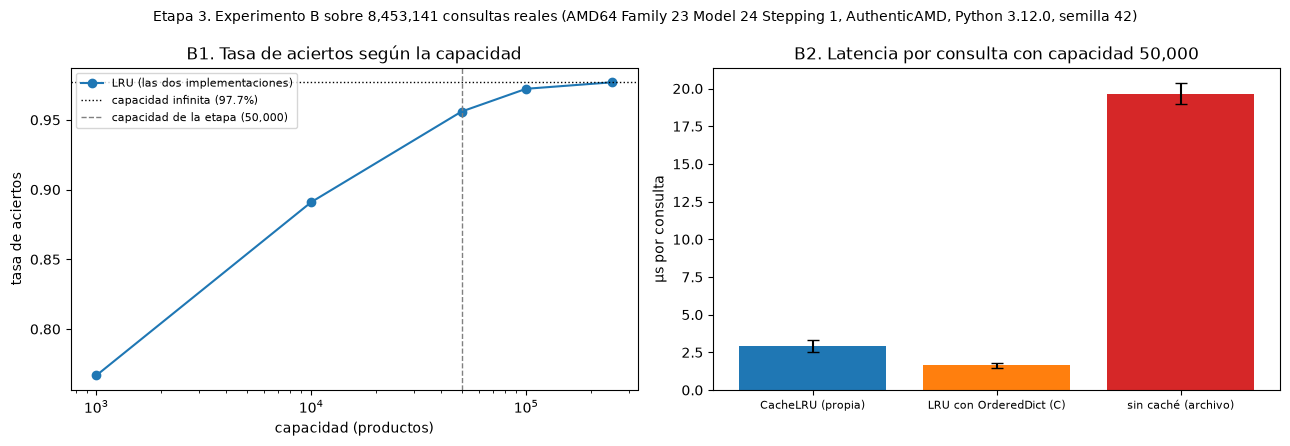

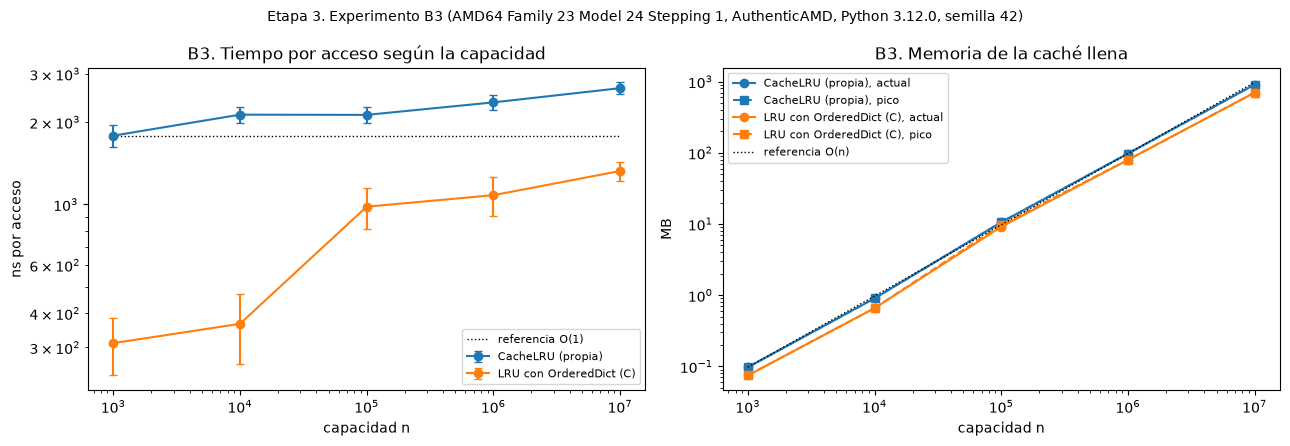

,metodo,pendiente_empirica,esperado,rango_n
0,CacheLRU (propia),0.04,≈0 (1),"1,000 a 10,000,000"
1,LRU con OrderedDict (C),0.17,≈0 (1),"1,000 a 10,000,000"


,metodo,pendiente_empirica,esperado,rango_n
0,CacheLRU (propia),1.0,≈1 (n),"1,000 a 10,000,000"
1,LRU con OrderedDict (C),1.0,≈1 (n),"1,000 a 10,000,000"


In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.plot(tasa_b1["capacidad"], tasa_b1["tasa_aciertos"], marker="o", label="LRU (las dos implementaciones)")
ax1.axhline(cota_superior, color="k", ls=":", lw=1, label=f"capacidad infinita ({cota_superior:.1%})")
ax1.axvline(CAPACIDAD_CACHE, color="gray", ls="--", lw=1, label=f"capacidad de la etapa ({CAPACIDAD_CACHE:,})")
ax1.set_xscale("log")
ax1.set_xlabel("capacidad (productos)")
ax1.set_ylabel("tasa de aciertos")
ax1.set_title("B1. Tasa de aciertos según la capacidad")
ax1.legend(fontsize=8)
ax2.bar(resumen_b2["metodo"], resumen_b2["us_por_consulta"], yerr=resumen_b2["desv_us"], capsize=4,
        color=["C0", "C1", "C3"])
ax2.set_ylabel("µs por consulta")
ax2.set_title(f"B2. Latencia por consulta con capacidad {CAPACIDAD_CACHE:,}")
ax2.tick_params(axis="x", labelsize=8)
plt.suptitle(f"Etapa 3. Experimento B sobre {len(secuencia):,} consultas reales ({plataforma_de(tiempos_b2)}, "
             f"semilla {SEED})", fontsize=10)
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "lru_stream.png", dpi=150)
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for metodo, datos in resumen_b3.groupby("metodo", sort=False):
    ax1.errorbar(datos["n"], datos["ns_por_operacion"], yerr=datos["desv_ns"], marker="o", capsize=3, label=metodo)
base = resumen_b3[resumen_b3["metodo"] == LRU_PROPIA].iloc[0]
referencia(ax1, TAMANOS_TODOS, base["n"], base["ns_por_operacion"], lambda n: n ** 0, "k:", "O(1)")
for metodo, datos in memoria_b3.groupby("metodo", sort=False):
    linea = ax2.plot(datos["n"], datos["actual_mb"], marker="o", label=f"{metodo}, actual")
    ax2.plot(datos["n"], datos["pico_mb"], marker="s", linestyle="--", color=linea[0].get_color(),
             label=f"{metodo}, pico")
base = memoria_b3[memoria_b3["metodo"] == LRU_PROPIA].iloc[0]
referencia(ax2, TAMANOS_TODOS, base["n"], base["actual_mb"], lambda n: n, "k:", "O(n)")
ejes_loglog(ax1, "B3. Tiempo por acceso según la capacidad", "capacidad n", "ns por acceso")
ejes_loglog(ax2, "B3. Memoria de la caché llena", "capacidad n", "MB")
plt.suptitle(f"Etapa 3. Experimento B3 ({plataforma_de(tiempos_b3)}, semilla {SEED})", fontsize=10)
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "lru_escalabilidad.png", dpi=150)
plt.show()

display(pendientes(resumen_b3, "ns_por_operacion", {LRU_PROPIA: "≈0 (1)", "LRU con OrderedDict (C)": "≈0 (1)"}))
pendientes(memoria_b3, "actual_mb", {LRU_PROPIA: "≈1 (n)", "LRU con OrderedDict (C)": "≈1 (n)"})

### Experimento C. Matriz dispersa

Para medir de 1K a 10M con la misma estructura se generan interacciones sintéticas que reproducen proporciones medidas en el stream real del paso 6. El tamaño de 10M queda cerca del stream real, y la celda compara las dos matrices.

- **Usuarios.** Su número es el de interacciones dividido por las interacciones por usuario del stream real. Se eligen con probabilidad uniforme.
- **Celdas.** Cada par usuario-producto recibe en promedio las interacciones por celda del stream real, porque un recorrido de compra suma vista, carrito, compra y reseña sobre el mismo producto.
- **Productos.** Se eligen entre los productos del catálogo con una distribución de Zipf de exponente 1.1. La tabla de memoria muestra cuántos productos distintos resultan en cada tamaño.
- **Tipos de evento.** Con la frecuencia real de vistas, carritos, compras, reseñas y devoluciones, y su peso de la tabla del paso 5.
- **Orden.** Las interacciones se entregan en orden aleatorio, así que las de una misma celda se intercalan con las de otros usuarios, como en el stream.

Se mide lo siguiente.

- **Construcción de la DOK.** Propia frente a una DOK con `dict`. Debe ser O(n), con pendiente log-log cercana a 1.
- **Conversión a CSR.** Ordena las celdas con `sorted`, en O(nnz log nnz), y las recorre una vez. Su pendiente debe quedar entre 1 y 1.1.
- **Memoria.** Actual y pico de las dos DOK y de la conversión. La memoria actual de la conversión es la de la CSR, y su pico incluye la lista ordenada de celdas, que existe solo durante la conversión. La matriz densa se construye con numpy y se mide mientras ocupe menos de 1 GB. En los tamaños mayores se calcula como filas × columnas × 8 bytes.

In [20]:
interacciones_reales = sum(tipos[t] for t in PESOS)
USUARIOS_POR_INTERACCION = filas_matriz / interacciones_reales
INTERACCIONES_POR_CELDA = interacciones_reales / METRICAS["matriz"]["celdas_dok"]
FRECUENCIA_TIPO = {t: tipos[t] for t in PESOS}
N_PRODUCTOS = len(almacen)
EXPONENTE_ZIPF = 1.1
LIMITE_DENSA_BYTES = 1e9
DOK_PROPIA, DOK_DICT, CONVERSION = "DOK propia (MatrizDispersa)", "DOK con dict (C)", "conversión a CSR"
print(f"Stream real: {interacciones_reales:,} interacciones, {1 / USUARIOS_POR_INTERACCION:.2f} interacciones "
      f"por usuario, {INTERACCIONES_POR_CELDA:.2f} interacciones por celda")


def interacciones_sinteticas(n, semilla=SEED):
    """Tres listas paralelas (usuario, producto, peso) con las proporciones del stream real, en orden aleatorio."""
    rng = np.random.default_rng(semilla)
    n_celdas = max(1, round(n / INTERACCIONES_POR_CELDA))
    n_usuarios = max(1, round(n * USUARIOS_POR_INTERACCION))
    zipf = np.arange(1, N_PRODUCTOS + 1, dtype=np.float64) ** -EXPONENTE_ZIPF
    usuario_celda = rng.integers(0, n_usuarios, size=n_celdas)
    producto_celda = rng.choice(N_PRODUCTOS, size=n_celdas, p=zipf / zipf.sum())
    celda = rng.integers(0, n_celdas, size=n)             # celda de cada interacción, en orden aleatorio
    nombres_tipo = list(FRECUENCIA_TIPO)
    frecuencia = np.array([FRECUENCIA_TIPO[t] for t in nombres_tipo], dtype=np.float64)
    tipo = rng.choice(len(nombres_tipo), size=n, p=frecuencia / frecuencia.sum())
    usuarios = [f"U{i:09d}" for i in range(n_usuarios)]
    productos = [f"B{i:09d}" for i in range(N_PRODUCTOS)]
    pesos = [PESOS[t] for t in nombres_tipo]
    return ([usuarios[i] for i in usuario_celda[celda].tolist()],
            [productos[i] for i in producto_celda[celda].tolist()],
            [pesos[i] for i in tipo.tolist()])


def construir_dok_propia(datos):
    matriz = MatrizDispersa()
    for u, p, w in zip(*datos):
        matriz.sumar(u, p, w)
    return matriz


def construir_dok_dict(datos):
    filas, columnas, celdas = {}, {}, {}
    for u, p, w in zip(*datos):
        i = filas.setdefault(u, len(filas))
        j = columnas.setdefault(p, len(columnas))
        celdas[(i, j)] = celdas.get((i, j), 0.0) + w
    return celdas


# Las dos DOK acumulan los mismos valores en las mismas celdas
datos_prueba = interacciones_sinteticas(10_000)
dok_prueba, dict_prueba = construir_dok_propia(datos_prueba), construir_dok_dict(datos_prueba)
assert {(k >> 32, k & 0xFFFFFFFF): v for k, v in dok_prueba.celdas.items()} == dict_prueba
del datos_prueba, dok_prueba, dict_prueba
print("Las dos DOK dan el mismo resultado.")


def medir_c():
    filas = []
    for n in TAMANOS_TODOS:
        datos = interacciones_sinteticas(n)
        repeticiones = REPETICIONES if n <= TAMANOS[-1] else 1
        for rep in range(repeticiones):
            segundos, matriz_n = medir(construir_dok_propia, datos)
            filas.append({"metodo": DOK_PROPIA, "n": n, "repeticion": rep, "operaciones": n, "segundos": segundos})
            segundos, _ = medir(construir_dok_dict, datos)
            filas.append({"metodo": DOK_DICT, "n": n, "repeticion": rep, "operaciones": n, "segundos": segundos})
        for rep in range(repeticiones):
            segundos, _ = medir(matriz_n.a_csr)
            filas.append({"metodo": CONVERSION, "n": n, "repeticion": rep, "operaciones": n, "segundos": segundos})
        del datos, matriz_n
        print(f"n = {n:>10,} medido")
    return pd.DataFrame(filas)


def medir_memoria_c():
    filas = []
    for n in TAMANOS_TODOS:
        datos = interacciones_sinteticas(n)
        matriz_n, actual_propia, pico_propia = medir_memoria(construir_dok_propia, datos)
        dok_dict, actual_dict, pico_dict = medir_memoria(construir_dok_dict, datos)
        del dok_dict
        csr_n, actual_csr, pico_csr = medir_memoria(matriz_n.a_csr)
        n_filas, n_columnas = matriz_n.forma
        bytes_densa = n_filas * n_columnas * 8
        actual_densa = np.nan
        if bytes_densa < LIMITE_DENSA_BYTES:
            densa, actual_densa, _ = medir_memoria(np.zeros, (n_filas, n_columnas))
            del densa
        filas.append({"n": n, "filas_matriz": n_filas, "columnas_matriz": n_columnas,
                      "celdas_dok": len(matriz_n.celdas), "nnz_csr": csr_n.nnz,
                      "mb_dok_propia_actual": actual_propia / 1e6, "mb_dok_propia_pico": pico_propia / 1e6,
                      "mb_dok_dict_actual": actual_dict / 1e6, "mb_dok_dict_pico": pico_dict / 1e6,
                      "mb_csr_actual": actual_csr / 1e6, "mb_csr_pico": pico_csr / 1e6,
                      "mb_csr_arreglos": csr_n.bytes() / 1e6,
                      "mb_densa_medida": actual_densa / 1e6, "mb_densa_calculada": bytes_densa / 1e6})
        del datos, matriz_n, csr_n
        print(f"n = {n:>10,} medido")
    return pd.DataFrame(filas)


tiempos_c = resultados(CARPETA_RESULTADOS / "matriz_tiempos.csv", medir_c)
memoria_c = resultados(CARPETA_RESULTADOS / "matriz_memoria.csv", medir_memoria_c)
resumen_c = resumir(tiempos_c)
corrida_unica(resumen_c)
display(resumen_c.round({"promedio_s": 6, "desv_est_s": 6, "ns_por_operacion": 1, "desv_ns": 1}))
memoria_c["densidad"] = memoria_c["nnz_csr"] / (memoria_c["filas_matriz"] * memoria_c["columnas_matriz"])
memoria_c.drop(columns=["procesador", "python"]).round(3)

Stream real: 8,438,123 interacciones, 7.69 interacciones por usuario, 3.89 interacciones por celda
Las dos DOK dan el mismo resultado.
n =      1,000 medido
n =     10,000 medido
n =    100,000 medido
n =  1,000,000 medido
n = 10,000,000 medido
Resultados guardados en results/etapa_3/matriz_tiempos.csv
n =      1,000 medido
n =     10,000 medido
n =    100,000 medido
n =  1,000,000 medido
n = 10,000,000 medido
Resultados guardados en results/etapa_3/matriz_memoria.csv
Construcciones con 10M, una corrida: 1.7 min de medición. 100 repeticiones tomarían unas 2.8 h solo en tiempo, sin contar la pasada de memoria.


,metodo,n,promedio_s,desv_est_s,ns_por_operacion,desv_ns,repeticiones
0,DOK propia (MatrizDispersa),1000,0.006285,0.001567,6284.7,1566.5,100
1,DOK con dict (C),1000,0.000516,0.000253,516.0,253.5,100
2,conversión a CSR,1000,0.000378,0.000123,378.4,122.7,100
3,DOK propia (MatrizDispersa),10000,0.057715,0.004789,5771.5,478.9,100
4,DOK con dict (C),10000,0.005976,0.001806,597.6,180.6,100
5,conversión a CSR,10000,0.003823,0.001578,382.3,157.8,100
6,DOK propia (MatrizDispersa),100000,0.690226,0.044118,6902.3,441.2,100
7,DOK con dict (C),100000,0.094391,0.019530,943.9,195.3,100
8,conversión a CSR,100000,0.055811,0.011479,558.1,114.8,100
9,DOK propia (MatrizDispersa),1000000,7.013575,0.179170,7013.6,179.2,100


,n,filas_matriz,columnas_matriz,celdas_dok,nnz_csr,mb_dok_propia_actual,mb_dok_propia_pico,mb_dok_dict_actual,mb_dok_dict_pico,mb_csr_actual,mb_csr_pico,mb_csr_arreglos,mb_densa_medida,mb_densa_calculada,densidad
0,1000,105,165,250,246,0.045,0.045,0.030,0.037,0.018,0.021,0.004,0.139,0.139,0.014
1,10000,1109,1138,2472,2436,0.421,0.421,0.321,0.373,0.152,0.197,0.038,10.096,10.096,0.002
2,100000,11093,7845,24674,24381,3.749,5.253,3.801,4.547,0.505,1.978,0.381,696.197,696.197,0.000
3,1000000,111016,47219,246353,243574,34.305,42.831,34.612,40.380,4.044,19.628,3.811,NaN,41936.516,0.000
4,10000000,1113156,232212,2464756,2437120,296.413,336.485,318.725,357.173,39.499,197.544,38.151,NaN,2067905.449,0.000


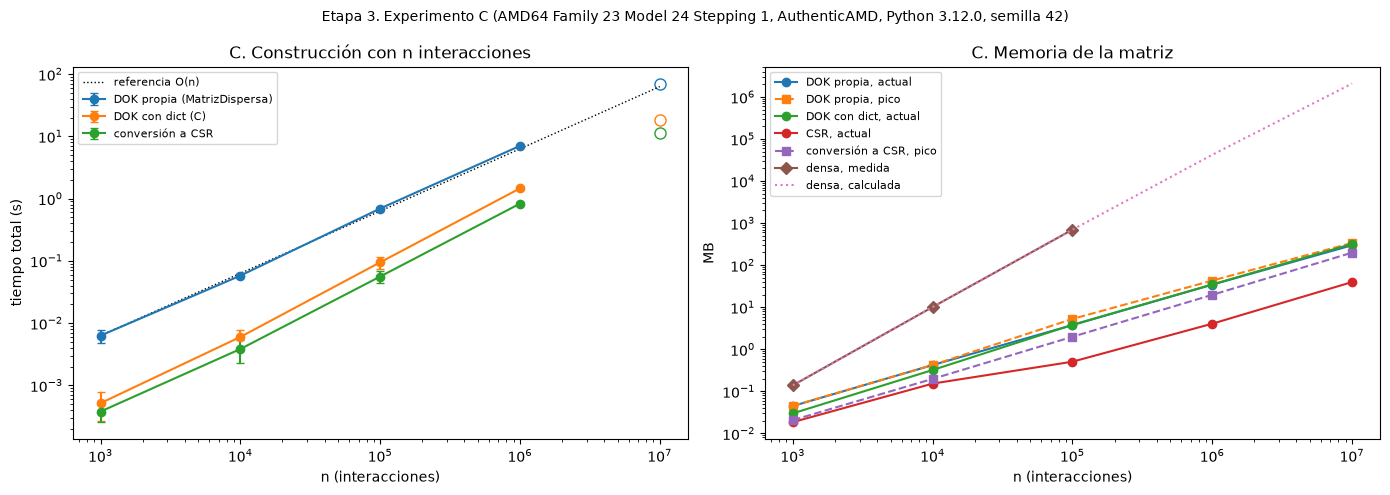

Matriz sintética con 10,000,000 interacciones: 1,113,156 usuarios × 232,212 productos, 2,464,756 celdas en la DOK, CSR de 38.2 MB, densa de 2.07 TB
Matriz real del paso 6 con 8,438,123 interacciones: 1,096,990 usuarios × 195,019 productos, 2,169,391 celdas en la DOK, CSR de 34.8 MB, densa de 1.71 TB


,metodo,pendiente_empirica,esperado,rango_n
0,DOK propia (MatrizDispersa),1.02,≈1 (n),"1,000 a 1,000,000"
1,DOK con dict (C),1.15,≈1 (n),"1,000 a 1,000,000"
2,conversión a CSR,1.12,≈1-1.1 (nnz log nnz),"1,000 a 1,000,000"


,metodo,pendiente_empirica,esperado,rango_n
0,"DOK propia, actual",0.96,≈1 (nnz),"1,000 a 10,000,000"
1,"CSR, actual",0.81,≈1 (nnz),"1,000 a 10,000,000"
2,"densa, calculada",1.80,>1 (filas × columnas),"1,000 a 10,000,000"


In [21]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for metodo, datos in resumen_c.groupby("metodo", sort=False):
    repetidas = datos[datos["n"] <= TAMANOS[-1]]
    barras = ax1.errorbar(repetidas["n"], repetidas["promedio_s"], yerr=repetidas["desv_est_s"], marker="o",
                          capsize=3, label=metodo)
    unica = datos[datos["n"] == N_UNICO]
    ax1.plot(unica["n"], unica["promedio_s"], marker="o", markerfacecolor="none", markersize=8, linestyle="none",
             color=barras[0].get_color())
base = resumen_c[resumen_c["metodo"] == DOK_PROPIA].iloc[0]
referencia(ax1, TAMANOS_TODOS, base["n"], base["promedio_s"], lambda n: n, "k:", "O(n)")
for columna, etiqueta, estilo in [("mb_dok_propia_actual", "DOK propia, actual", "o-"),
                                  ("mb_dok_propia_pico", "DOK propia, pico", "s--"),
                                  ("mb_dok_dict_actual", "DOK con dict, actual", "o-"),
                                  ("mb_csr_actual", "CSR, actual", "o-"),
                                  ("mb_csr_pico", "conversión a CSR, pico", "s--"),
                                  ("mb_densa_medida", "densa, medida", "D-"),
                                  ("mb_densa_calculada", "densa, calculada", ":")]:
    ax2.plot(memoria_c["n"], memoria_c[columna], estilo, label=etiqueta)
ejes_loglog(ax1, "C. Construcción con n interacciones", "n (interacciones)", "tiempo total (s)")
ejes_loglog(ax2, "C. Memoria de la matriz", "n (interacciones)", "MB")
plt.suptitle(f"Etapa 3. Experimento C ({plataforma_de(tiempos_c)}, semilla {SEED})", fontsize=10)
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "matriz_escalabilidad.png", dpi=150)
plt.show()

sintetica = memoria_c[memoria_c["n"] == N_UNICO].iloc[0]
print(f"Matriz sintética con {N_UNICO:,} interacciones: {int(sintetica['filas_matriz']):,} usuarios × "
      f"{int(sintetica['columnas_matriz']):,} productos, {int(sintetica['celdas_dok']):,} celdas en la DOK, "
      f"CSR de {sintetica['mb_csr_arreglos']:.1f} MB, densa de {sintetica['mb_densa_calculada'] / 1e6:.2f} TB")
print(f"Matriz real del paso 6 con {interacciones_reales:,} interacciones: {filas_matriz:,} usuarios × "
      f"{columnas_matriz:,} productos, {METRICAS['matriz']['celdas_dok']:,} celdas en la DOK, "
      f"CSR de {METRICAS['matriz']['bytes_csr'] / 1e6:.1f} MB, densa de {METRICAS['matriz']['bytes_densa'] / 1e12:.2f} TB")

display(pendientes(resumen_c, "promedio_s", {DOK_PROPIA: "≈1 (n)", DOK_DICT: "≈1 (n)",
                                             CONVERSION: "≈1-1.1 (nnz log nnz)"}, hasta=TAMANOS[-1]))
pd.concat([pendientes(memoria_c.assign(metodo=nombre), columna, {nombre: esperado})
           for nombre, columna, esperado in [("DOK propia, actual", "mb_dok_propia_actual", "≈1 (nnz)"),
                                             ("CSR, actual", "mb_csr_actual", "≈1 (nnz)"),
                                             ("densa, calculada", "mb_densa_calculada", ">1 (filas × columnas)")]],
          ignore_index=True)

### Verificación del protocolo

La celda comprueba que las mediciones de tiempo guardadas tienen 100 repeticiones de 1K a 1M, que las mediciones por bloque tienen 100 también en 10M y que las construcciones con 10M tienen una corrida.

In [22]:
REPETICIONES_PEDIDAS = 100       # el enunciado pide 100 repeticiones cuando sea viable


def comprobar(tabla, columnas, una_corrida):
    """Cada combinación tiene 100 repeticiones, salvo las que cumplen una_corrida, que tienen una."""
    for clave, repeticiones in tabla.groupby(columnas)["segundos"].count().items():
        fila = dict(zip(columnas, clave if isinstance(clave, tuple) else (clave,)))
        esperado = 1 if una_corrida(fila) else REPETICIONES_PEDIDAS
        assert repeticiones == esperado, f"{fila}: {repeticiones} repeticiones, se esperaban {esperado}"


comprobar(tiempos_a, ["operacion", "metodo", "n"], lambda f: f["operacion"] == "construccion" and f["n"] == N_UNICO)
comprobar(tiempos_b2, ["metodo"], lambda f: False)
comprobar(tiempos_b3, ["metodo", "n"], lambda f: False)
comprobar(tiempos_c, ["metodo", "n"], lambda f: f["n"] == N_UNICO)
print("Las mediciones de tiempo tienen 100 repeticiones de 1K a 1M. En 10M, las mediciones por bloque tienen 100 "
      "repeticiones y las construcciones una corrida.")

Las mediciones de tiempo tienen 100 repeticiones de 1K a 1M. En 10M, las mediciones por bloque tienen 100 repeticiones y las construcciones una corrida.


### Lectura de los resultados

Los valores citados corresponden a la ejecución guardada en `results/etapa_3/`, con la plataforma del paso 1. Los conteos, las tasas de aciertos y las dimensiones de las matrices dependen solo de los datos y de la semilla, y la memoria medida con `tracemalloc` depende además de la versión de Python. Una ejecución anterior de este notebook en otra máquina (Intel64 Family 6 Model 186, Python 3.12.10) obtuvo los mismos 8 080 834 aciertos y 372 307 fallos de la caché, 195 019 productos con estado, 2 169 391 celdas en la matriz y 50 906 reposiciones, las mismas cinco tasas de aciertos del experimento B1, el mismo pico de 516 MB de la etapa y la misma memoria de la tabla hash y de la DOK con 1M elementos (61.7 MB y 34.3 MB). Los tiempos absolutos cambian con la máquina.

- **Índice del catálogo.** Con 710 503 productos la tabla tiene 1 048 576 posiciones y un factor de carga de 0.678. El sondeo medio medido es 2.048 posiciones, frente a 2.051 de la fórmula de Knuth, así que CRC32 reparte las claves como supone el análisis. El índice ocupa 135.1 MB en memoria, unos 190 bytes por producto, y los registros completos quedan en el archivo de 303 MB.
- **Etapa completa.** Procesa 9 940 617 eventos en 202 s, 20.3 µs por evento con la lectura y decodificación del archivo incluidas. La primera pasada, que solo lee el archivo, tarda 71 s. Sin contar el índice del catálogo, la etapa ocupa 500 MB al terminar y 516 MB de pico. La caché acierta el 95.6 % de las 8 453 141 consultas y lee el disco 372 307 veces.
- **Stock sintético.** De las 1 978 936 compras, 73 678 (3.7 %) llegan sin stock, en 11 785 productos, y hay 50 906 reposiciones. Los parámetros del stock no salen del dataset y deben ajustarse si la etapa 9 muestra la disponibilidad.
- **A, construcción.** `TablaHash` tiene pendiente 1.05, coherente con O(n). Cada inserción cuesta entre 2.7 y 4.0 µs de 1K a 10M, con las reconstrucciones incluidas. `dict` es entre 9.5 y 34 veces más rápido por estar escrito en C. Su ventaja baja con n porque con millones de claves el acceso a memoria pasa a dominar su costo, lo que también explica su pendiente de 1.20. Con 10M, una construcción tarda 35.4 s con `TablaHash` y 3.7 s con `dict`. Las dos corridas con 10M suman 0.7 min, y 100 repeticiones tomarían 1.1 h.
- **A, consulta.** El tiempo por consulta de `TablaHash` pasa de 0.66 µs en 1K a 1.38 µs en 10M, con pendiente 0.08, y el de `dict` pasa de 49 a 585 ns, con pendiente 0.28. Las dos son O(1). El aumento se atribuye a que una tabla grande no cabe en la caché del procesador y cada consulta espera más a la memoria. La búsqueda lineal tiene pendiente 1.05, coherente con O(n). En 1M tarda 36.5 ms por consulta, unas 33 000 veces más que `TablaHash`.
- **A, memoria.** Las dos tablas ocupan memoria O(n), con pendientes de 0.95 y 1.02. Al terminar la construcción, `TablaHash` ocupa entre 55 y 96 bytes por clave y `dict` entre 47 y 66. Con 10M, son 548.5 MB frente a 526.1 MB. La diferencia mayor está en el pico. En `TablaHash` es entre 1.06 y 1.94 veces la memoria actual, porque durante cada reconstrucción conviven los arreglos viejos y los nuevos, y con 10M llega a 878.2 MB. La tabla propia mantiene al menos un 30 % de posiciones libres y guarda claves y valores en dos listas separadas.
- **B1, tasa de aciertos.** Con 8 453 141 consultas sobre 195 019 productos distintos, la tasa sube de 76.7 % con 1 000 productos a 89.1 % con 10 000, 95.6 % con 50 000 y 97.2 % con 100 000. Con 250 000 llega a la cota de 97.7 %, porque todos los productos distintos caben en la caché. La capacidad de la etapa, 50 000, alcanza el 97.9 % de la cota con el 25.6 % de los productos distintos, y duplicarla sube la tasa solo 1.6 puntos. Las dos implementaciones dan los mismos aciertos, y con 50 000 coinciden con los de la ejecución del paso 6.
- **B2, latencia en el stream real.** Con capacidad 50 000, `CacheLRU` responde en 2.93 µs por consulta, 6.7 veces menos que los 19.7 µs de la lectura del archivo sin caché. La LRU con `OrderedDict` responde en 1.64 µs, 1.8 veces menos que la propia, con la misma tasa de aciertos en los bloques medidos (95.8 %). Como el archivo cabe en la caché de páginas del sistema operativo, la variante sin caché mide sobre todo la llamada al sistema y la decodificación del JSON. Con lecturas que llegaran al disco, su costo sería mayor.
- **B3, escalabilidad.** El tiempo por acceso de `CacheLRU` pasa de 1.78 µs con capacidad 1K a 2.66 µs con 10M, con pendiente 0.04, coherente con O(1). El de `OrderedDict` pasa de 0.31 a 1.32 µs, con pendiente 0.17 y un salto entre 10K y 100K, que se atribuye a que su tabla deja de caber en la caché del procesador. La tasa de aciertos de los bloques queda entre 90.85 % y 90.94 % en todos los tamaños, igual a la esperada de 90.9 %. La memoria de la caché llena es O(n), con pendiente 1.0 en las dos. `CacheLRU` ocupa entre 90 y 106 bytes por elemento y `OrderedDict` entre 66 y 91. Con 10M, son 908.4 MB frente a 700.3 MB. En `CacheLRU` la memoria pico coincide con la actual, porque su tabla se crea con la capacidad final y no se reconstruye mientras se llena.
- **C, construcción.** La DOK propia tiene pendiente 1.02, coherente con O(n), y cuesta entre 5.8 y 7.0 µs por interacción. La DOK con `dict` es entre 3.8 y 12 veces más rápida. Su ventaja baja con n por la misma razón que en A, y su pendiente es 1.15. La conversión a CSR tiene pendiente 1.12. Entre 1K y 1M, una curva n log n da una pendiente de 1.10, y el exceso se atribuye al acceso a memoria con n grande. Con 10M, la DOK propia tarda 70.2 s, la DOK con `dict` 18.6 s y la conversión 11.3 s. Las tres corridas con 10M suman 1.7 min, y 100 repeticiones tomarían 2.8 h.
- **C, memoria.** Con 1M interacciones, la DOK propia ocupa 34.3 MB (42.8 MB de pico), casi lo mismo que la DOK con `dict` (34.6 MB y 40.4 MB de pico), y la CSR ocupa 4.0 MB, 8.5 veces menos. Con 10M, la DOK propia ocupa 296.4 MB, menos que los 318.7 MB de la DOK con `dict`, y la CSR 39.5 MB. El pico de la conversión es unas 5 veces la CSR final (197.5 MB con 10M), por la lista ordenada de celdas que existe mientras dura la conversión. La pendiente de la memoria es 0.96 en la DOK y 0.81 en la CSR. La de la CSR queda por debajo de 1 porque en 1K y 10K domina un costo fijo; entre 1M y 10M la CSR crece 9.8 veces con 10 veces más celdas. La matriz densa medida con numpy coincide con el cálculo filas × columnas × 8 bytes hasta 100K (696.2 MB). Su pendiente calculada es 1.80, porque crece con el producto de usuarios y productos.
- **Matriz sintética y real.** Con 10M interacciones sintéticas la matriz tiene 1 113 156 usuarios × 232 212 productos y 2 464 756 celdas, cerca de la matriz real del paso 6, que tiene 1 096 990 × 195 019 y 2 169 391 celdas a partir de 8 438 123 interacciones. La CSR sintética ocupa 38.2 MB y la real 34.8 MB. Las matrices densas equivalentes ocuparían 2.07 TB y 1.71 TB.

Las tres estructuras propias cumplen las complejidades teóricas. La tabla hash construye en O(n) y consulta en O(1), la caché LRU accede en O(1) con cualquier capacidad y la matriz dispersa se construye en O(n) y ocupa memoria proporcional a sus celdas. Se mantienen en la etapa porque son las estructuras evaluadas del bloque S4. `dict` y `OrderedDict` quedan como referencia de lo que se ganaría con una implementación en C, entre 1.8 y 34 veces en tiempo según la operación y el tamaño. Con 10M, la memoria de las estructuras propias está entre 0.93 y 1.30 veces la de sus equivalentes en C.

## Paso 8. Salida de la etapa 3

La etapa produce cuatro salidas en `data/interim/<CATEGORIA>/etapa_3/`.

| Archivo | Contenido | Etapas que lo usan |
| --- | --- | --- |
| `catalogo.jsonl` | Catálogo en disco, un registro por producto con el precio ya convertido | 4 (B+Tree sobre el archivo), 5 (atributos del vector), 9 (fichas de producto, uso previsto) |
| `estado_productos.parquet` | Contadores, stock, disponibilidad y precio observado de cada producto con actividad | 5 (popularidad como atributo), 9 (ranking por popularidad y disponibilidad, uso previsto) |
| `matriz_usuario_producto.npz` | Matriz CSR usuario × producto con los identificadores de filas y columnas | 7 (conjunto de usuarios de cada producto para MinHash), 9 (recomendaciones, uso previsto) |
| `metricas.json` | Métricas de la ejecución del paso 6 y plataforma | Informe y panel de la etapa 9 |

Las etapas siguientes también pueden importar `EtapaAlmacenamiento` desde `src/etapa_3/storage.py` para consultar productos en línea.

In [23]:
pq.write_table(pa.Table.from_pandas(estados, preserve_index=False), RUTA_ESTADOS, compression="zstd")
guardar_matriz(RUTA_MATRIZ, csr, etapa.matriz.usuarios, etapa.matriz.productos)
RUTA_METRICAS.write_text(json.dumps({**METRICAS, "plataforma": PLATAFORMA}, indent=2, ensure_ascii=False),
                         encoding="utf-8")

# Comprobación: la matriz guardada se lee igual
csr_leida, usuarios_leidos, productos_leidos = cargar_matriz(RUTA_MATRIZ)
assert (csr_leida.indptr == csr.indptr and csr_leida.indices == csr.indices and csr_leida.datos == csr.datos
        and usuarios_leidos == etapa.matriz.usuarios and productos_leidos == etapa.matriz.productos)

for ruta in (RUTA_CATALOGO, RUTA_ESTADOS, RUTA_MATRIZ, RUTA_METRICAS):
    tamano = ruta.stat().st_size
    print(f"{ruta_relativa(ruta)}: " + (f"{tamano / 1e6:,.1f} MB" if tamano >= 1e5 else f"{tamano / 1e3:,.1f} KB"))

data/interim/Office_Products/etapa_3/catalogo.jsonl: 303.1 MB
data/interim/Office_Products/etapa_3/estado_productos.parquet: 4.2 MB
data/interim/Office_Products/etapa_3/matriz_usuario_producto.npz: 38.0 MB
data/interim/Office_Products/etapa_3/metricas.json: 0.9 KB


### Datos para las etapas 7 y 9

Se muestran dos ejemplos de cómo las etapas siguientes usan la salida.

- **Etapa 7.** La transpuesta de la matriz da, para cada producto, el conjunto de usuarios que interactuaron con él. Ese conjunto es la entrada de MinHash para estimar la similitud de Jaccard entre productos.
- **Etapa 9 (uso previsto).** La fila de un usuario en la CSR da los productos con los que interactuó y su peso, que es la base de sus recomendaciones.

In [24]:
transpuesta = csr.transpuesta()
usuarios_por_producto = np.diff(np.frombuffer(transpuesta.indptr, dtype=np.int64))
productos_por_usuario = np.diff(np.frombuffer(csr.indptr, dtype=np.int64))
print(f"Usuarios por producto: media {usuarios_por_producto.mean():.2f}, máximo {usuarios_por_producto.max()}")
print(f"Productos por usuario: media {productos_por_usuario.mean():.2f}, máximo {productos_por_usuario.max()}")

i = int(productos_por_usuario.argmax())
columnas, pesos = csr.fila(i)
pd.DataFrame({"parent_asin": [etapa.matriz.productos[j] for j in columnas], "peso": list(pesos),
              "titulo": [etapa.ficha(etapa.matriz.productos[j])["title"][:70] for j in columnas]}
             ).sort_values("peso", ascending=False).head(10)

Usuarios por producto: media 11.12, máximo 2929
Productos por usuario: media 1.98, máximo 1557


,parent_asin,peso,titulo
12,B0B3MX7LVG,20.0,"EZlifego Double Sided Tape Heavy Duty, Extra L..."
30,B09PWTVGPW,12.0,"Alientape Nano Double Sided Tape, Multipurpose..."
272,B09YK1YBZ6,12.0,Jeff Kinney Diary of a Wimpy Kid 1-16 Books Bo...
169,B09NR9SYPF,12.0,The Original Everlasting Comfort Foot Rest for...
411,B0BG4Z8YY1,12.0,"Bonsaii 14-Sheet Microcut Paper Shredder, 60-M..."
8,B0BN478RWJ,12.0,HP DeskJet 2755e Wireless Color All-in-One Pri...
82,B07SQRQMKX,12.0,Canon CL-244 color cartridge Compatible to iP2...
124,B07YQXNFBB,12.0,Homall Office Chair High Back Computer Desk Ch...
814,B09V2S9QJV,8.0,CAGIE Leather Vintage Journal for Men Soft Cov...
1188,B0BLJN5HNQ,8.0,Lanxivi 5 PCS Gel Pens Quick Dry Ink Pens Blac...


## Resumen de la etapa 3

| Aspecto | Decisión |
| --- | --- |
| Tabla hash | Direccionamiento abierto con sondeo lineal, CRC32, lápidas y reconstrucción con factor de carga 0.7. O(1) esperado |
| Catálogo | Archivo de registros en disco con índice hash `parent_asin` → `(offset, largo)` |
| Caché | LRU propia (tabla hash + lista doblemente enlazada), capacidad 50 000 productos, O(1) por operación |
| Estado del producto | Contadores, stock sintético con reposición a las 48 h y precio observado, solo para productos con actividad |
| Matriz | Usuario × producto con pesos por tipo de evento. DOK durante el stream y CSR al cerrar |
| Salida | Catálogo en disco, estado de productos, matriz CSR y métricas en `data/interim/<CATEGORIA>/etapa_3/` |

Referencias. Cormen, T. H., Leiserson, C. E., Rivest, R. L., y Stein, C. (2022). *Introduction to Algorithms* (4.ª ed.), cap. 11. Knuth, D. E. (1998). *The Art of Computer Programming, Vol. 3: Sorting and Searching* (2.ª ed.), sec. 6.4. Saad, Y. (2003). *Iterative Methods for Sparse Linear Systems* (2.ª ed.), sec. 3.4. Mattson, R. L., Gecsei, J., Slutz, D. R., y Traiger, I. L. (1970). Evaluation techniques for storage hierarchies. *IBM Systems Journal*, 9(2), 78-117.